# Лабораторна робота № 7
## Діагностика моделей: відхилення, дисперсія, розбіжність даних і пріоритизація помилок

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали · лекції 9–10

---

### Постановка

Ви — аналітик сервісу, який читає рукописні цифри з бланків. Перші моделі навчали на
**сканах**: 20 000 чітких цифр. Тепер клієнти надсилають **фото з телефона**, і модель на них
помиляється значно частіше. У кожного варіанта — свій «телефон»: свої вади зйомки, яких вам
ніхто не опише.

Попередній аналітик залишив **виробничу модель** і пішов. Вам треба:

1. **поставити діагноз** виробничій моделі: відхилення, дисперсія чи розбіжність даних;
2. **знайти і впорядкувати за впливом** причини помилок на телефонних фото;
3. **скласти план дій** з обмеженим бюджетом і перевірити його числами.

> **Головне правило лабораторної.** Кожне твердження у звіті підкріплюється числом, яке ви
> отримали в цьому ноутбуці. «Модель перенавчилась» без двох похибок поруч — не діагноз.

| Частина | Що робите | Бали |
|---|---|---|
| 1 | відхилення і дисперсія: чотири вибірки, людський рівень, криві навчання, дії | 1,5 |
| 2 | різні розподіли: розклад похибки, аналіз 100 помилок, ліки з бюджетом, план, аналіз за частинами, критика звіту колеги | 2,0 |
| 3 | звіт і декларація про використання ШІ | 0,5 |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Осінна Єлизавета Сергіївна'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 8      # номер у списку групи

In [2]:
assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
print('варіант', VARIANT)

варіант 8


> Поряд із ноутбуком має лежати тека `дані/` з файлами `скани.npz`,
> `lr7_варіанти_студенту.json` і **файлом вашого варіанта** `lr7_варіант_NN.npz`
> (кожен варіант — окремий файл близько 5 МБ; завантажте свій із ВНС).

In [3]:
import importlib.util, subprocess, sys
REQUIRED = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib']
MODNAME = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [4]:
import warnings; warnings.filterwarnings('ignore')
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
import sklearn
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

DATA_DIR = 'дані'
C1, C2, C3, C4, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#c0392b', '#8a8a8a'
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 90)
print('scikit-learn', sklearn.__version__, '| numpy', np.__version__)

scikit-learn 1.9.1 | numpy 2.5.3


### Допоміжні функції

Їх не треба змінювати — лише розуміти, що вони роблять. Опис кожної — у рядку документації.

In [5]:
import numpy as np
from scipy import ndimage as ndi


def flat(X):
    """Зображення uint8 (n, 28, 28) → ознаки у [0, 1], форма (n, 784)."""
    return X.reshape(len(X), -1).astype(np.float32) / 255.0


def split_train_dev(n, n_dev, seed=7):
    """Індекси навчальної частини і навчально-валідаційної вибірки (training dev set)."""
    perm = np.random.default_rng(seed).permutation(n)
    return perm[n_dev:], perm[:n_dev]


def _rotate(im, deg):
    t = np.deg2rad(deg); mat = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
    c = np.array(im.shape) / 2 - 0.5
    return ndi.affine_transform(im, mat, offset=c - mat @ c, order=1, mode='constant', cval=0.0)


def distort(X, seed, angle=None, blur=None, lowres=None, background=None, contrast=None, glare=None, noise=None, share=1.0):
    """Синтез «телефонних» фото з чистих цифр. Кожен параметр — пара (від, до), з якої
    для кожного зображення береться випадкове значення; None — властивість вимкнено.
    share — частка зображень, до яких застосовують задані властивості (решта лишається чистою).
      angle      — кут повороту, градуси (знак обирається випадково)
      blur       — сигма гаусового розмиття, пікселі
      lowres     — до якої роздільності стиснути і розтягнути назад, пікселі (наприклад, (9, 12))
      background — яскравість фону, 0..1;  contrast — множник яскравості штрихів, 0..1
      glare      — сила відблиску (пляма, у якій штрихи «вигорають» до кольору фону), 0..1
      noise      — стандартне відхилення шуму сенсора
    Повертає uint8 (n, 28, 28)."""
    rng = np.random.default_rng(seed); out = np.empty(X.shape, np.float32)
    yy, xx = np.mgrid[0:28, 0:28]
    u = lambda r: rng.uniform(*r)
    for k, im in enumerate(X.astype(np.float32) / 255):
        if rng.random() < share:
            if angle: im = _rotate(im, rng.choice([-1, 1]) * u(angle))
            if blur: im = ndi.gaussian_filter(im, u(blur))
            if lowres:
                L = int(round(u(lowres))); im = ndi.zoom(ndi.zoom(im, L / 28, order=1), 28 / L, order=1)[:28, :28]
            bg = u(background) if background else 0.0
            im = bg + (u(contrast) if contrast else 1.0) * im
            if glare:
                cy, cx = rng.uniform(8, 20, 2); sg = rng.uniform(3.5, 6.5)
                w = u(glare) * np.exp(-((yy - cy) ** 2 + (xx - cx) ** 2) / (2 * sg * sg)); im = im * (1 - w) + w * bg
            if noise: im = im + rng.normal(0, u(noise), im.shape)
        out[k] = np.clip(im, 0, 1)
    return (out * 255).round().astype(np.uint8)


def image_stats(X):
    """Прості вимірювання кожного фото за пікселями — ними можна відбирати фото без міток."""
    rows = []
    yy, xx = np.mgrid[0:28, 0:28]
    for im in X.astype(np.float32) / 255:
        p50, p99 = np.percentile(im, [50, 99]); ink = np.clip(im - p50, 0, None); m = ink.sum() + 1e-9
        cy, cx = (ink * yy).sum() / m, (ink * xx).sum() / m
        mu20, mu02, mu11 = (ink * (xx - cx) ** 2).sum() / m, (ink * (yy - cy) ** 2).sum() / m, (ink * (xx - cx) * (yy - cy)).sum() / m
        rows.append({'контраст': p99 - p50,
                     'різкість': float(ndi.laplace(ndi.gaussian_filter(im, 0.5)).var()),
                     'нахил_осі': float(np.degrees(0.5 * np.arctan2(2 * mu11, mu02 - mu20))),
                     'шум': float((im - ndi.median_filter(im, 3)).std()),
                     'частка_чорнила': float((im > p50 + 0.5 * (p99 - p50)).mean())})
    return rows


def make_canvas(photos, seed, blobs=(1, 3), lines=0):
    """Полотна 56×56: телефонне фото цифри в довільному місці; плями-завади поза цифрою
    і (за потреби) lines горизонтальних ліній бланка. Повертає полотна (float 0..1) і справжні положення."""
    r = np.random.default_rng(seed); n = len(photos)
    X = np.clip(0.1 + r.normal(0, 0.04, (n, 56, 56)), 0, 1).astype(np.float32); pos = np.zeros((n, 2), int)
    yy, xx = np.mgrid[0:56, 0:56]
    for i in range(n):
        rr, cc = r.integers(0, 29, 2); pos[i] = (rr, cc)
        X[i, rr:rr + 28, cc:cc + 28] = np.maximum(X[i, rr:rr + 28, cc:cc + 28], photos[i].astype(np.float32) / 255)
        for _ in range(r.integers(blobs[0], blobs[1] + 1)):
            while True:
                br, bc = r.integers(2, 54, 2)
                if not (rr - 3 <= br <= rr + 30 and cc - 3 <= bc <= cc + 30):
                    break
            s, a = r.uniform(1.2, 2.2), r.uniform(0.5, 0.9)
            X[i] = np.maximum(X[i], 0.1 + a * np.exp(-((yy - br) ** 2 + (xx - bc) ** 2) / (2 * s * s)))
        for _ in range(lines):
            ly = r.integers(4, 52); X[i, ly:ly + 2, :] = np.maximum(X[i, ly:ly + 2, :], r.uniform(0.45, 0.7))
    return np.clip(X, 0, 1), pos


def locate(X, thr=0.3):
    """Компонент A (без навчання): лівий верхній кут вирізу 28×28 навколо цифри."""
    out = np.zeros((len(X), 2), int)
    for i, im in enumerate(X):
        ink = np.clip(ndi.gaussian_filter(im, 0.7) - thr, 0, None)
        s = ndi.uniform_filter(ink, size=28, mode='constant')[14:43, 14:43]
        r0, c0 = np.unravel_index(np.argmax(s), s.shape)
        w = ink[r0:r0 + 28, c0:c0 + 28].copy(); lab, n = ndi.label(w > 0)
        if n > 1:
            w[lab != 1 + np.argmax(ndi.sum(w, lab, range(1, n + 1)))] = 0
        m = w.sum() + 1e-9; cy = (w.sum(1) * np.arange(28)).sum() / m; cx = (w.sum(0) * np.arange(28)).sum() / m
        out[i] = (int(np.clip(round(r0 + cy - 14), 0, 28)), int(np.clip(round(c0 + cx - 14), 0, 28)))
    return out


def crop(X, pos):
    """Вирізи 28×28 у форматі uint8, як фото."""
    return (np.stack([X[i, p[0]:p[0] + 28, p[1]:p[1] + 28] for i, p in enumerate(pos)]) * 255).round().astype(np.uint8)


def shifted_copies(X, seed, k=2):
    """Копії зображень, зсунуті на випадкові ±k пікселів: класифікатор після локалізатора має їх витримувати."""
    r = np.random.default_rng(seed); out = np.empty_like(X)
    for i in range(len(X)):
        dy, dx = r.integers(-k, k + 1, 2); out[i] = np.roll(np.roll(X[i], dy, 0), dx, 1)
    return out

In [6]:
def err(model, X, y):
    """Похибка у відсотках (частка неправильних відповідей × 100)."""
    return round(100 * float((model.predict(X) != y).mean()), 2)


def show_grid(images, titles=None, ncol=10, size=1.05, title=None):
    """Сітка зображень; темне — чорнило."""
    n = len(images); nrow = (n + ncol - 1) // ncol
    fig, axs = plt.subplots(nrow, ncol, figsize=(size * ncol, size * nrow + (0.35 if title else 0) + 0.25 * nrow))
    for k, ax in enumerate(np.ravel(axs)):
        ax.axis('off')
        if k < n:
            ax.imshow(images[k], cmap='gray_r', vmin=0, vmax=255 if np.asarray(images[k]).max() > 1 else 1)
            if titles:
                ax.set_title(titles[k], fontsize=8)
    if title:
        fig.suptitle(title, fontsize=10)
    plt.tight_layout(); plt.show()


_TEST_CALLS = []


def evaluate_on_test(model, name):
    """Остаточна оцінка на тестовій вибірці. Викликайте ОДИН раз — для обраної моделі."""
    _TEST_CALLS.append(name)
    if len(_TEST_CALLS) > 1:
        print('УВАГА: тестову вибірку використано вже', len(_TEST_CALLS), 'рази — це буде видно у звіті')
    return err(model, flat(TEST_X), TEST_Y)

### Дані

| Масив | Що це | Скільки |
|---|---|---|
| `SCAN_X`, `SCAN_Y` | скани: чіткі цифри | 20 000 |
| `PHONE_X`, `PHONE_Y` | телефонні фото з мітками, для навчання | 2000 |
| `POOL_X`, `POOL_Y` | телефонні фото, які можна **докупити** (частина 2; бюджет — 1000 штук) | 2000 |
| `DEV_X`, `DEV_Y` | валідаційна вибірка: телефонні фото | 1500 |
| `TEST_X`, `TEST_Y` | тестова вибірка: телефонні фото — **лише для остаточної оцінки** | 1500 |
| `HUMAN_X` | 50 фото для вимірювання людського рівня (мітки приховано) | 50 |

Валідаційна і тестова вибірки — з того розподілу, на якому сервіс має працювати:
телефонні фото (лекція 10, розділ 36).

In [7]:
S = np.load(os.path.join(DATA_DIR, 'скани.npz'))
V = np.load(os.path.join(DATA_DIR, 'lr7_варіант_%02d.npz' % VARIANT))
with open(os.path.join(DATA_DIR, 'lr7_варіанти_студенту.json'), encoding='utf-8') as f:
    INFO = json.load(f)[VARIANT - 1]
SCAN_X, SCAN_Y = S['scan_X'], S['scan_y']
PHONE_X, PHONE_Y = V['phone_train_X'], V['phone_train_y']
POOL_X, POOL_Y = V['pool_X'], V['pool_y']
DEV_X, DEV_Y = V['dev_X'], V['dev_y']
TEST_X, TEST_Y = V['test_X'], V['test_y']
HUMAN_X, HUMAN_CODE = V['human_X'], V['human_code']
for nm in ['SCAN_X', 'PHONE_X', 'POOL_X', 'DEV_X', 'TEST_X', 'HUMAN_X']:
    print('%-8s' % nm, globals()[nm].shape)
print()
print('Виробнича модель попереднього аналітика:')
print('  навчена на:', INFO['виробнича']['навчена_на'])
print('  модель:    ', INFO['виробнича']['модель'])

SCAN_X   (20000, 28, 28)
PHONE_X  (2000, 28, 28)
POOL_X   (2000, 28, 28)
DEV_X    (1500, 28, 28)
TEST_X   (1500, 28, 28)
HUMAN_X  (50, 28, 28)

Виробнича модель попереднього аналітика:
  навчена на: скани
  модель:     MLPClassifier(hidden_layer_sizes=(256,), max_iter=30, random_state=0)


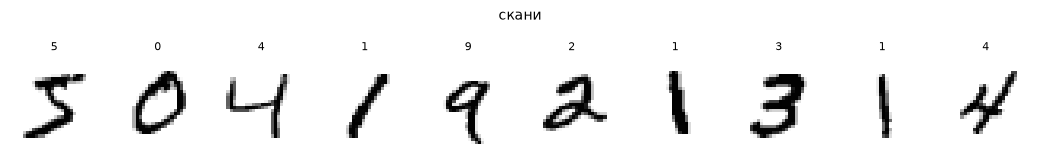

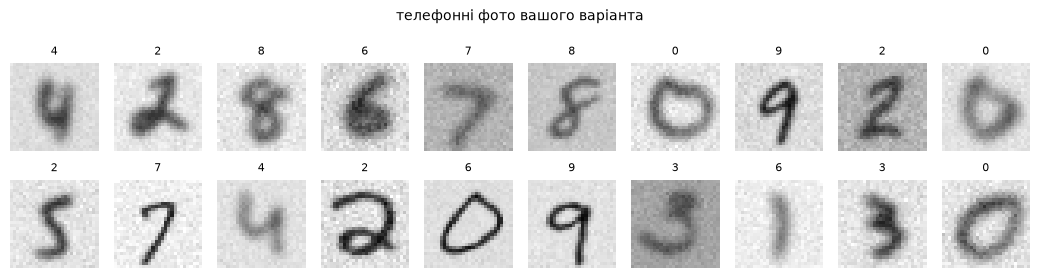

In [8]:
show_grid(SCAN_X[:10], [str(v) for v in SCAN_Y[:10]], title='скани')
show_grid(PHONE_X[:20], [str(v) for v in PHONE_Y[:20]], title='телефонні фото вашого варіанта')

---
# Частина 1. Відхилення і дисперсія (1,5 бала)
---
## 1. Чотири вибірки

Щоб розрізнити дисперсію і розбіжність даних, потрібна **навчально-валідаційна вибірка**
(training dev set): приклади з **того самого розподілу, на якому вчилася модель**, але не
показані їй під час навчання (лекція 10, розділ 40).

Виробнича модель навчалась на джерелі, назва якого надрукована вище. Оберіть те саме
джерело і відкладіть із нього навчально-валідаційну вибірку:

| джерело | що це | скільки відкласти |
|---|---|---|
| `'скани'` | лише 20 000 сканів | 2000 |
| `'телефон'` | лише 2000 телефонних фото | 400 |
| `'суміш'` | 20 000 сканів + 2000 фото | 2000 |

### Завдання 1.1

In [9]:
# ----- ВАШІ ВІДПОВІДІ -----
TRAIN_SOURCE = 'скани'     # 'скани' / 'телефон' / 'суміш'
# чому навчально-валідаційну вибірку треба брати саме звідси, а не з телефонних фото:
WHY_TRAIN_DEV = ('Виробнича модель навчалась лише на 20 000 сканів, тому й навчально-валідаційну вибірку (2000 прикладів) '
                 'відкладено зі сканів: це той самий розподіл, що й навчальний, але приклади моделі не показували. '
                 'Тоді різниця навчально-валідаційної і навчальної похибок вимірює саме дисперсію. '
                 'Якби взяти її з телефонних фото, змішалися б дисперсія і розбіжність даних, і розрізнити їх було б неможливо.')
# ----- КІНЕЦЬ -----

In [10]:
SOURCES = {'скани': (SCAN_X, SCAN_Y), 'телефон': (PHONE_X, PHONE_Y),
           'суміш': (np.concatenate([SCAN_X, PHONE_X]), np.concatenate([SCAN_Y, PHONE_Y]))}
N_TRAIN_DEV = {'скани': 2000, 'телефон': 400, 'суміш': 2000}
assert TRAIN_SOURCE in SOURCES, 'оберіть одне з трьох джерел'
assert WHY_TRAIN_DEV, 'поясніть вибір'
SRC_X, SRC_Y = SOURCES[TRAIN_SOURCE]
idx_tr, idx_td = split_train_dev(len(SRC_Y), N_TRAIN_DEV[TRAIN_SOURCE])
X_tr, y_tr = flat(SRC_X[idx_tr]), SRC_Y[idx_tr]
X_td, y_td = flat(SRC_X[idx_td]), SRC_Y[idx_td]
X_dev, y_dev = flat(DEV_X), DEV_Y
print(f'навчальна: {len(y_tr)} | навчально-валідаційна: {len(y_td)} | валідаційна: {len(y_dev)} | тестова: {len(TEST_Y)} (не чіпаємо)')

навчальна: 18000 | навчально-валідаційна: 2000 | валідаційна: 1500 | тестова: 1500 (не чіпаємо)


#### Пояснення до виконаного

Спершу я розділила дані на частини. Навчальна вибірка потрібна для навчання. Навчально-валідаційну вибірку (2000 прикладів) я відклала з того ж джерела, на якому вчилась модель, тобто зі сканів, і модель її не бачила. Вона дозволяє відрізнити дисперсію (погана робота на нових прикладах з того ж розподілу) від розбіжності даних (погана робота на прикладах з іншого розподілу). Валідаційна і тестова вибірки складаються з телефонних фото, бо саме на такому розподілі сервіс має працювати. Тестову вибірку я використала лише один раз, наприкінці, щоб остаточна оцінка була чесною.

## 2. Людський рівень

Оптимальну похибку ми не знаємо, тож оцінюємо її **людським рівнем** — найкращим, якого
досягає людина на тих самих фото (лекція 10, розділи 33–34). Подивіться на 50 фото свого
варіанта і впишіть цифри підряд — 50 символів, пробіли не важливі. Не збільшуйте зображення
більше, ніж його бачить модель, і не підглядайте в мітки.

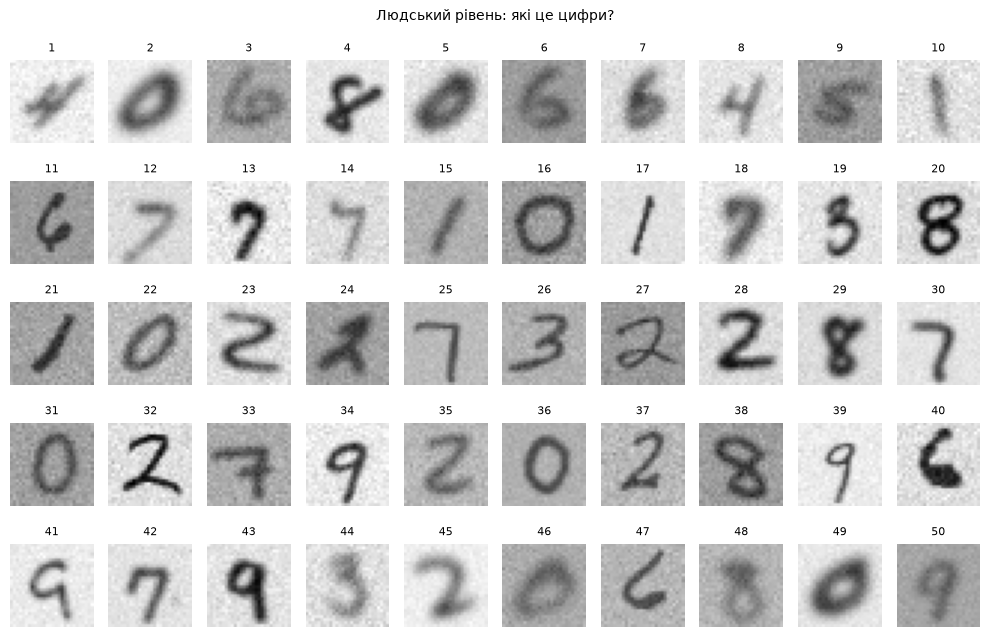

In [11]:
show_grid(HUMAN_X, [str(k + 1) for k in range(50)], size=1.0, title='Людський рівень: які це цифри?')

### Завдання 2.1

In [12]:
# ----- ВАШІ ВІДПОВІДІ -----
HUMAN_ANSWERS = '4068066451 6777101938 1022732287 0279202896 9793206809'    # 50 цифр по порядку
# ----- КІНЕЦЬ -----

In [13]:
ans = [int(c) for c in HUMAN_ANSWERS if c.isdigit()]
assert len(ans) == 50, f'потрібно 50 цифр, а введено {len(ans)}'
truth = (HUMAN_CODE - 7 * np.arange(50)) % 10
HUMAN_ERR = round(100 * float(np.mean(np.array(ans) != truth)), 1)
print('ваша похибка на 50 фото:', HUMAN_ERR, '%')
print('номери фото, де ви помилились:', [k + 1 for k in range(50) if ans[k] != truth[k]])

ваша похибка на 50 фото: 2.0 %
номери фото, де ви помилились: [18]


#### Пояснення до виконаного

Окремо я оцінила людський рівень: розпізнала 50 фото вручну й помилилась один раз, тобто 2 %. Це наближена оцінка найменшої досяжної похибки. Вона не дуже точна, бо вибірка мала, але служить орієнтиром, з яким порівнюють модель.

> **Одна помилка на 50 фото — це 2 %, і довірчий інтервал такої оцінки широкий.**
> Як людський рівень беріть найкращий результат, якого досягла людина на цих фото: якщо
> одногрупник із тим самим варіантом має менше помилок — використайте його число і
> зазначте це у звіті.

## 3. Діагноз виробничої моделі

Відтворюємо виробничу модель і рахуємо похибки на трьох вибірках. Розклад (лекція 10, розділ 41):

$$\underbrace{E_{\text{навч}} - E_{\text{людина}}}_{\text{усувне відхилення}},\qquad
\underbrace{E_{\text{навч-вал}} - E_{\text{навч}}}_{\text{дисперсія}},\qquad
\underbrace{E_{\text{вал}} - E_{\text{навч-вал}}}_{\text{розбіжність даних}}$$

In [14]:
PRODUCTION = eval(INFO['виробнича']['модель'])        # модель саме в тому вигляді, як її записав попередній аналітик
t0 = time.time()
prod = PRODUCTION.fit(X_tr, y_tr)
E_PROD = {'навч': err(prod, X_tr, y_tr), 'навч_вал': err(prod, X_td, y_td), 'вал': err(prod, X_dev, y_dev)}
print(f'навчено за {time.time() - t0:.0f} с')
print('похибки виробничої моделі, %:', E_PROD)
DECOMP_PROD = {'усувне відхилення': round(E_PROD['навч'] - HUMAN_ERR, 2),
               'дисперсія': round(E_PROD['навч_вал'] - E_PROD['навч'], 2),
               'розбіжність даних': round(E_PROD['вал'] - E_PROD['навч_вал'], 2)}
pd.Series(DECOMP_PROD, name='п. п.').to_frame()

навчено за 24 с
похибки виробничої моделі, %: {'навч': 0.0, 'навч_вал': 3.9, 'вал': 62.87}


,п. п.
усувне відхилення,-2.00
дисперсія,3.90
розбіжність даних,58.97


### Завдання 3.1

Поставте діагноз. Якщо дві складові близькі, назвіть головну і поясніть, чому друга —
другорядна.

In [15]:
# ----- ВАШІ ВІДПОВІДІ -----
DIAGNOSIS = 'розбіжність'        # 'відхилення' / 'дисперсія' / 'розбіжність'
# доказ числами (дві похибки поруч і різниця між ними):
DIAGNOSIS_WHY = (f"Похибка на навчально-валідаційній вибірці (скани) {E_PROD['навч_вал']} %, на валідаційній (телефонні фото) {E_PROD['вал']} %: "
                 f"різниця {DECOMP_PROD['розбіжність даних']} п. п. — це розбіжність даних. Дисперсія лише {DECOMP_PROD['дисперсія']} п. п. "
                 f"({E_PROD['навч']} % → {E_PROD['навч_вал']} %), а усувне відхилення {DECOMP_PROD['усувне відхилення']} п. п. "
                 f"(навчальна {E_PROD['навч']} % проти людського рівня {HUMAN_ERR} % — модель на навчальних даних навіть краща за людину). "
                 f"Модель добре працює на скановах цифрах, але майже не вміє читати телефонні фото.")
# ----- КІНЕЦЬ -----

In [16]:
assert DIAGNOSIS in ('відхилення', 'дисперсія', 'розбіжність') and DIAGNOSIS_WHY, 'заповніть діагноз і доказ'
print('діагноз:', DIAGNOSIS)

діагноз: розбіжність


#### Пояснення до виконаного

Далі я поставила діагноз виробничій моделі. Похибку розкладають на три складові: усувне відхилення (навчальна похибка мінус людський рівень), дисперсію (навчально-валідаційна мінус навчальна) і розбіжність даних (валідаційна мінус навчально-валідаційна). Виміряні похибки: на навчальних даних 0 %, на навчально-валідаційних 3,9 %, на валідаційних, тобто телефонних фото, 62,87 %. Відхилення вийшло −2 п. п., тобто від'ємним, бо на навчальних даних модель навіть краща за людину, а це означає, що фактично його немає. Дисперсія становить 3,9 п. п., розбіжність даних 58,97 п. п. Отже, головна проблема — розбіжність даних: модель добре працює на розподілі сканів і погано на розподілі телефонних фото, бо навчальні дані мало схожі на реальні.

## 4. Крива навчання

Крива навчання показує, чи допоможуть **ще дані того самого розподілу** (лекція 9, розділи 28–30).
Навчаємо виробничу модель на 10, 25, 50 і 100 % навчальної частини і дивимось на похибку на
навчальній і навчально-валідаційній вибірках; пунктиром — валідаційна похибка повної моделі
і ваш людський рівень. Це триває 1–3 хвилини.

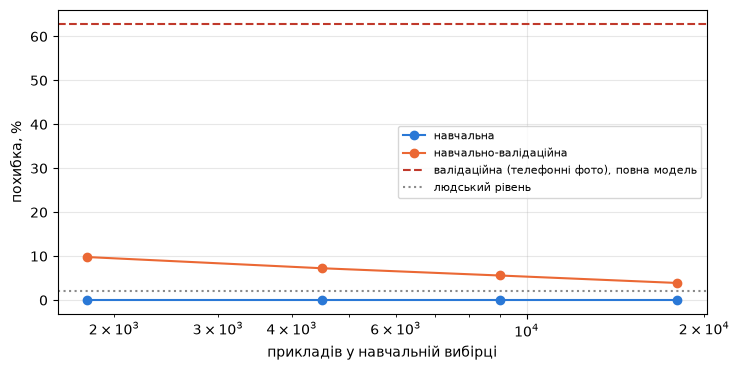

,n,навч,навч_вал
0,1800,0.0,9.80
1,4500,0.0,7.25
2,9000,0.0,5.60
3,18000,0.0,3.90


In [17]:
curve = []
for frac in [0.1, 0.25, 0.5, 1.0]:
    n = max(50, int(len(y_tr) * frac))
    m = eval(INFO['виробнича']['модель']).fit(X_tr[:n], y_tr[:n])
    curve.append({'n': n, 'навч': err(m, X_tr[:n], y_tr[:n]), 'навч_вал': err(m, X_td, y_td)})
CURVE = pd.DataFrame(curve)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(CURVE['n'], CURVE['навч'], 'o-', color=C1, label='навчальна')
ax.plot(CURVE['n'], CURVE['навч_вал'], 'o-', color=C2, label='навчально-валідаційна')
ax.axhline(E_PROD['вал'], ls='--', color=C4, label='валідаційна (телефонні фото), повна модель')
ax.axhline(HUMAN_ERR, ls=':', color=GREY, label='людський рівень')
ax.set_xscale('log'); ax.set_xlabel('прикладів у навчальній вибірці'); ax.set_ylabel('похибка, %')
ax.legend(fontsize=8); ax.grid(alpha=.3); plt.tight_layout(); plt.show()
CURVE

### Завдання 4.1

In [18]:
# ----- ВАШІ ВІДПОВІДІ -----
MORE_SAME_DATA_HELPS = False   # True / False: чи зменшать валідаційну похибку ще дані ТОГО САМОГО джерела?
# що на графіку це показує (форма двох кривих, розрив між ними, де валідаційна лінія):
CURVE_WHY = (f"Навчальна похибка весь час {CURVE['навч'].iloc[-1]} %, а навчально-валідаційна падає зі збільшенням даних: "
             f"{CURVE['навч_вал'].iloc[0]} % ({CURVE['n'].iloc[0]} прикладів) → {CURVE['навч_вал'].iloc[1]} % → {CURVE['навч_вал'].iloc[2]} % → {CURVE['навч_вал'].iloc[3]} % ({CURVE['n'].iloc[3]}). "
             f"Тобто більше сканів ще трохи зменшує дисперсію (розрив {CURVE['навч_вал'].iloc[-1]} п. п. при повних даних і далі скорочується), але ця крива показує лише похибку на СКАНАХ. "
             f"Валідаційна лінія — телефонні фото — лежить на {E_PROD['вал']} %, тобто на {round(E_PROD['вал']-CURVE['навч_вал'].iloc[-1],1)} п. п. вище навчально-валідаційної, "
             f"і ця різниця — розбіжність даних, а не брак сканів: навіть при нескінченній кількості сканів лінія на скановому розподілі не опуститься нижче людського рівня {HUMAN_ERR} %, "
             f"а для фото вона нічого не обіцяє. Тому відповідь на питання про валідаційну (фото) — ні.")
# ----- КІНЕЦЬ -----

In [19]:
assert MORE_SAME_DATA_HELPS in (True, False) and CURVE_WHY, 'заповніть висновок за кривою'

#### Пояснення до виконаного

Щоб перевірити, чи допоможуть додаткові дані того самого джерела, я побудувала криву навчання: навчала модель на 10, 25, 50 і 100 відсотках навчальної частини. Навчально-валідаційна похибка зі збільшенням вибірки зменшується (з 9,8 % на 1800 прикладів до 3,9 % на 18 000), тобто більше сканів ще трохи зменшує дисперсію. Але ця крива показує похибку лише на сканах. Валідаційна похибка на телефонних фото при цьому лишається на 59 п. п. вище, і ніякі додаткові скани цей розрив не закриють, бо вони з іншого розподілу. Тож відповідь на питання, чи допоможуть дані того самого джерела, — ні, принаймні для телефонних фото.

## 5. Дії: що допомагає, а що — ні

Таблиці лекції 9 (розділи 25 і 27) кажуть, які дії зменшують відхилення, а які — дисперсію;
лекція 10 (розділи 37–43) — що робити з розбіжністю. Перевірте це на своїй моделі:

* **дві дії**, які, за вашим діагнозом, мають допомогти;
* **одну контрольну дію**, спрямовану на **іншу** проблему, — вона допомогти не повинна.

Кожна дія — це модель і навчальні дані. Похибки рахуються на тих самих навчально-валідаційній
і валідаційній вибірках, що й у пункті 3. Готові «цеглинки»:
`X_tr, y_tr` — навчальна частина вашого джерела; `flat(SCAN_X), SCAN_Y` — усі скани;
`flat(PHONE_X), PHONE_Y` — усі телефонні фото (увага: частина з них — у навчально-валідаційній
вибірці, якщо джерело `'телефон'` чи `'суміш'`; використовуйте `X_tr` і додавайте до нього
лише те, чого в ній немає); `SRC_X[idx_tr]` — ті самі навчальні приклади як зображення, з яких
`shifted_copies(SRC_X[idx_tr], seed, k)` робить копії, зсунуті на ±k пікселів (аугментація);
`distort(...)` — синтез «телефонних» фото (опис — у розділі 8).

Приклад запису:

```python
('більша модель: MLP(256)', 'відхилення',
 MLPClassifier(hidden_layer_sizes=(256,), max_iter=30, random_state=0), X_tr, y_tr)
```

Одна дія навчається від кількох секунд до хвилини.

In [20]:
# ----- ВАШІ ВІДПОВІДІ -----
# Параметри синтезу «телефонних» фото (докладно підбираються у розділі 8)
ACT_SYN = dict(angle=(0, 30), blur=(0.4, 1.4), background=(0.05, 0.45), contrast=(0.25, 1.0), noise=(0.02, 0.05))
ACT_SYN_X = distort(SRC_X[idx_tr], seed=3, share=1.0, **ACT_SYN)
ACTIONS = [
    # (назва дії, на яку проблему спрямована, модель, навчальні X, навчальні y)
    ('+2000 справжніх телефонних фото в навчання', 'розбіжність',
     MLPClassifier(hidden_layer_sizes=(256,), max_iter=30, random_state=0),
     np.concatenate([X_tr, flat(PHONE_X)]), np.concatenate([y_tr, PHONE_Y])),
    ('+18 000 синтетичних телефонних фото (distort)', 'розбіжність',
     MLPClassifier(hidden_layer_sizes=(256,), max_iter=30, random_state=0),
     np.concatenate([X_tr, flat(ACT_SYN_X)]), np.concatenate([y_tr, y_tr])),
    ('контроль: більша мережа MLP(512)', 'відхилення',
     MLPClassifier(hidden_layer_sizes=(512,), max_iter=30, random_state=0), X_tr, y_tr),
    ('контроль: сильніша регуляризація alpha=0,1', 'дисперсія',
     MLPClassifier(hidden_layer_sizes=(256,), alpha=0.1, max_iter=30, random_state=0), X_tr, y_tr),
]
# ----- КІНЕЦЬ -----

In [21]:
assert len(ACTIONS) >= 3, 'потрібно щонайменше три дії: дві за діагнозом і одна контрольна'
rows = [{'дія': 'виробнича модель (до змін)', 'на що спрямована': '—', **E_PROD}]
for name, target, model, Xa, ya in ACTIONS:
    t0 = time.time(); model.fit(Xa, ya)
    rows.append({'дія': name, 'на що спрямована': target, 'навч': err(model, Xa, ya),
                 'навч_вал': err(model, X_td, y_td), 'вал': err(model, X_dev, y_dev)})
    print(f'{name}: {time.time() - t0:.0f} с')
ACT_TABLE = pd.DataFrame(rows)
ACT_TABLE['Δ дисперсії, п. п.'] = (ACT_TABLE['навч_вал'] - ACT_TABLE['навч']) - (E_PROD['навч_вал'] - E_PROD['навч'])
ACT_TABLE['Δ відхилення, п. п.'] = ACT_TABLE['навч'] - E_PROD['навч']
ACT_TABLE['Δ валідаційної, п. п.'] = ACT_TABLE['вал'] - E_PROD['вал']
ACT_TABLE.round(2)

+2000 справжніх телефонних фото в навчання: 25 с
+18 000 синтетичних телефонних фото (distort): 48 с
контроль: більша мережа MLP(512): 55 с
контроль: сильніша регуляризація alpha=0,1: 28 с


,дія,на що спрямована,навч,навч_вал,вал,"Δ дисперсії, п. п.","Δ відхилення, п. п.","Δ валідаційної, п. п."
0,виробнича модель (до змін),—,0.00,3.90,62.87,0.00,0.00,0.00
1,+2000 справжніх телефонних фото в навчання,розбіжність,0.64,3.65,11.27,-0.89,0.64,-51.60
2,+18 000 синтетичних телефонних фото (distort),розбіжність,2.30,3.20,10.13,-3.00,2.30,-52.74
3,контроль: більша мережа MLP(512),відхилення,0.00,3.50,51.40,-0.40,0.00,-11.47
4,"контроль: сильніша регуляризація alpha=0,1",дисперсія,0.12,3.55,42.80,-0.47,0.12,-20.07


### Завдання 5.1

In [22]:
# ----- ВАШІ ВІДПОВІДІ -----
_a = ACT_TABLE.set_index('дія')
_r, _s, _b, _g = (_a.loc[n] for n in ['+2000 справжніх телефонних фото в навчання', '+18 000 синтетичних телефонних фото (distort)',
                                       'контроль: більша мережа MLP(512)', 'контроль: сильніша регуляризація alpha=0,1'])
ACTIONS_CONCLUSION = (f"Діагноз — розбіжність даних, тому дві дії наближають навчальні дані до телефонних фото. "
    f"Справжні фото: валідаційна {E_PROD['вал']} % → {_r['вал']} % ({_r['Δ валідаційної, п. п.']:+.2f} п. п.). "
    f"Синтез: {E_PROD['вал']} % → {_s['вал']} % ({_s['Δ валідаційної, п. п.']:+.2f} п. п.); навчальна при цьому зросла до {_s['навч']} % (відхилення {_s['Δ відхилення, п. п.']:+.2f} п. п.) — модель тепер вчить складнішу суміш. "
    f"Контрольні дії проти відхилення (MLP(512): {_b['вал']} %, {_b['Δ валідаційної, п. п.']:+.2f} п. п.) і проти дисперсії (alpha=0,1: {_g['вал']} %, {_g['Δ валідаційної, п. п.']:+.2f} п. п.) "
    f"зачепили ту складову, якої майже немає: відхилення {E_PROD['навч']} %, дисперсія {DECOMP_PROD['дисперсія']} п. п., і її зміна становить лише {_b['Δ дисперсії, п. п.']:+.2f} / {_g['Δ дисперсії, п. п.']:+.2f} п. п. "
    f"Прогноз «не допоможе» справдився лише частково: валідаційна на фото таки впала (регуляризація і ширша мережа роблять модель менш крихкою на незнайомих фото), "
    f"проте залишилась {_b['вал']} % і {_g['вал']} % проти {_r['вал']} % і {_s['вал']} % у дій проти розбіжності — вони дають у 2,5–5 разів менше. Лікувати треба дані.")
# ----- КІНЕЦЬ -----

In [23]:
assert ACTIONS_CONCLUSION, 'сформулюйте висновок'

#### Пояснення до виконаного

Після цього я перевірила діагноз експериментально. Для цього взяла дві дії, які за діагнозом мають допомогти, і дві контрольні, спрямовані на інші складові. Перша дія — додати до навчання 2000 справжніх телефонних фото: валідаційна похибка впала з 62,87 % до 11,27 %. Друга — додати 18 000 синтетичних фото, створених зі сканів функцією, що імітує нахил, розмиття, тьмяність і шум: похибка впала до 10,13 %. Контрольними діями були збільшення мережі до 512 нейронів (проти відхилення) і посилення регуляризації (проти дисперсії). Вони теж трохи знизили валідаційну похибку, до 51,4 % і 42,8 %, але ефект у 2,5–5 разів слабший, а самі відхилення та дисперсія майже не змінились, бо й були малими. Мій прогноз, що контрольні дії не допоможуть, справдився лише частково. Проте висновок однозначний: проблема в даних, а не в самій моделі.

---
# Частина 2. Різні розподіли і пріоритизація помилок (2,0 бала)
---
## 6. Модель B і розклад її похибки

Далі працюємо з моделлю, яку радить лекція 10 (розділ 37): велика мережа на **суміші** сканів і
телефонних фото. Навчально-валідаційна вибірка — 2000 прикладів суміші.

навчено за 24 с; похибки моделі B, %: {'навч': 0.55, 'навч_вал': 4.35, 'вал': 11.93}


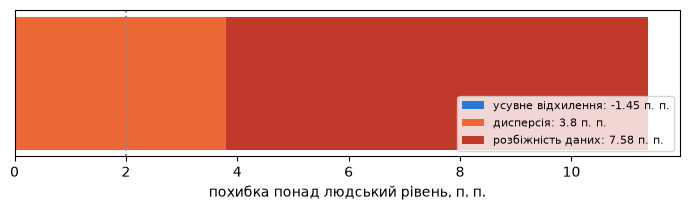

In [24]:
MIX_X, MIX_Y = SOURCES['суміш']
mix_tr, mix_td = split_train_dev(len(MIX_Y), 2000)
XB_tr, yB_tr = flat(MIX_X[mix_tr]), MIX_Y[mix_tr]
XB_td, yB_td = flat(MIX_X[mix_td]), MIX_Y[mix_td]


def model_b():
    return MLPClassifier(hidden_layer_sizes=(256,), max_iter=30, random_state=0)


t0 = time.time()
B = model_b().fit(XB_tr, yB_tr)
pred_B = B.predict(X_dev)
E_B = {'навч': err(B, XB_tr, yB_tr), 'навч_вал': err(B, XB_td, yB_td), 'вал': err(B, X_dev, y_dev)}
print(f'навчено за {time.time() - t0:.0f} с; похибки моделі B, %:', E_B)
DECOMP_B = {'усувне відхилення': round(E_B['навч'] - HUMAN_ERR, 2), 'дисперсія': round(E_B['навч_вал'] - E_B['навч'], 2),
            'розбіжність даних': round(E_B['вал'] - E_B['навч_вал'], 2)}
fig, ax = plt.subplots(figsize=(7, 2.2))
left = 0
for (k, v), c in zip(DECOMP_B.items(), [C1, C2, C4]):
    ax.barh(0, max(v, 0), left=left, color=c, label=f'{k}: {v} п. п.'); left += max(v, 0)
ax.axvline(HUMAN_ERR, color=GREY, ls=':'); ax.set_yticks([]); ax.set_xlabel('похибка понад людський рівень, п. п.')
ax.legend(fontsize=8, loc='lower right'); plt.tight_layout(); plt.show()

### Завдання 6.1

In [25]:
# ----- ВАШІ ВІДПОВІДІ -----
DIAGNOSIS_B = 'розбіжність'      # 'відхилення' / 'дисперсія' / 'розбіжність'
# чому саме це і чому більше сканів тут не допоможе (або допоможе):
DIAGNOSIS_B_WHY = (f"Модель B: навчальна {E_B['навч']} %, навчально-валідаційна {E_B['навч_вал']} %, валідаційна {E_B['вал']} %; людський рівень {HUMAN_ERR} %. "
                   f"Розклад: відхилення {DECOMP_B['усувне відхилення']} п. п. (від'ємне — модель на навчальних даних краща за людину, тобто фактично 0), "
                   f"дисперсія {DECOMP_B['дисперсія']} п. п., розбіжність {DECOMP_B['розбіжність даних']} п. п. Головна складова — розбіжність, "
                   f"дисперсія друга (близько 60 % від розбіжності) і другорядна. Додаткові скани лише поглиблюють перекіс до чистих зображень "
                   f"і не вчать модель дефектів телефонної зйомки, тому розбіжність не зменшать (у виробничій моделі скани дали {E_PROD['вал']} % на фото).")
# ----- КІНЕЦЬ -----

In [26]:
assert DIAGNOSIS_B in ('відхилення', 'дисперсія', 'розбіжність') and DIAGNOSIS_B_WHY

#### Пояснення до виконаного

Далі я працювала з моделлю B, яку навчили на суміші сканів і телефонних фото. Її похибки: 0,55 % на навчальній вибірці, 4,35 % на навчально-валідаційній і 11,93 % на валідаційній. Складові розкладу: відхилення −1,45 п. п. (фактично нуль), дисперсія 3,8 п. п., розбіжність даних 7,58 п. п. Головною лишається розбіжність, дисперсія друга. Додаткові скани її не зменшать: вони не містять дефектів телефонної зйомки, а модель їх уже вивчила.

## 7. Аналіз 100 помилок

Метод лекції 9 (розділи 14–19) і лекції 10 (розділ 42): переглянути помилки **очима**,
позначити, що з кожним фото не так, і порахувати, скільки дасть усунення кожної причини.

Нижче — перші 100 помилок моделі B на валідаційній вибірці (у порядку номерів фото). Над
кожним фото: порядковий номер помилки, **мітка → прогноз моделі**.

**Словник категорій** (можна кілька через `+`):

| категорія | як виглядає |
|---|---|
| `нахил` | цифра помітно повернута |
| `розмиття` | штрихи розмиті, краї нечіткі |
| `низька роздільність` | «сходинки», цифра наче з кількох великих пікселів |
| `тьмяність` | сірий фон, блідий слабкий штрих |
| `відблиск` | частина штриха «вигоріла» до кольору фону |
| `шум` | зерно, крапки по всьому фото |
| `хибна мітка:N` | модель, схоже, права, а мітка хибна; N — правильна, на вашу думку, цифра |
| `нерозбірливо` | людина теж не впевнена |
| `інше` | нічого з переліченого |

Приклад: `'нахил+шум'`, `'хибна мітка:4'`, `'інше'`.

помилок моделі B на валідаційній вибірці:

 179 | переглядаємо: 100


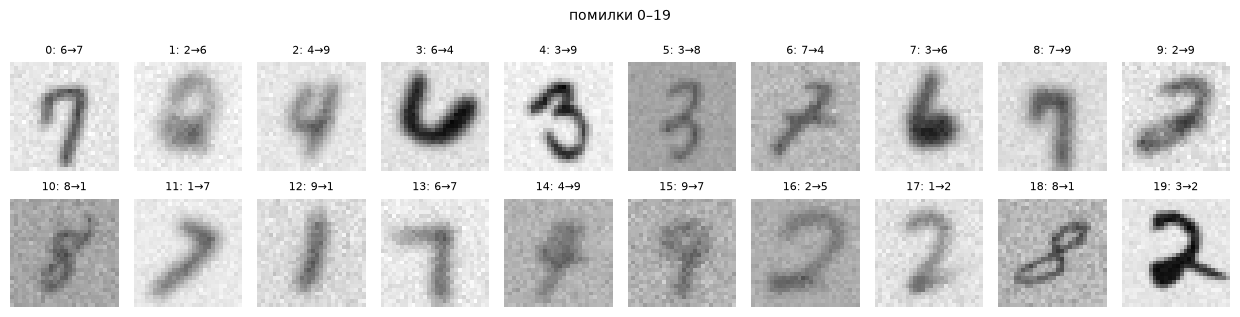

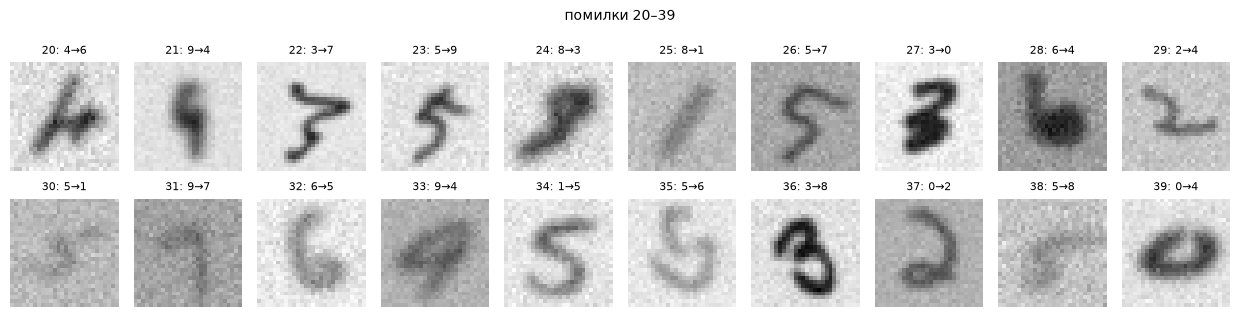

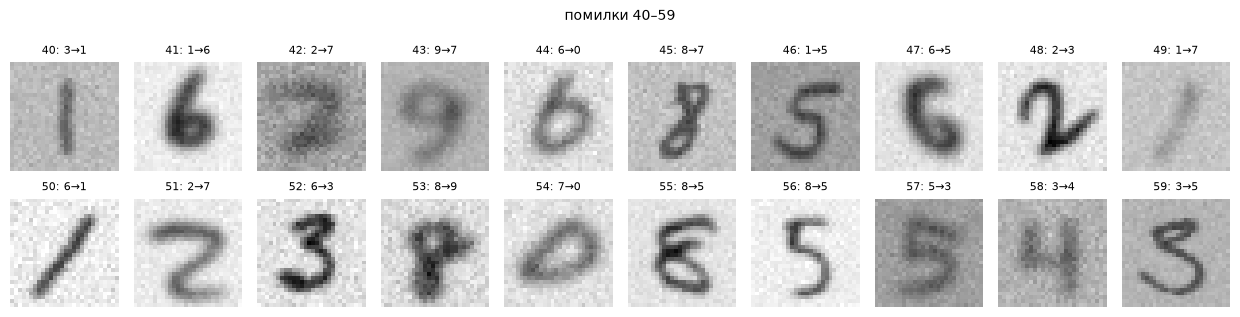

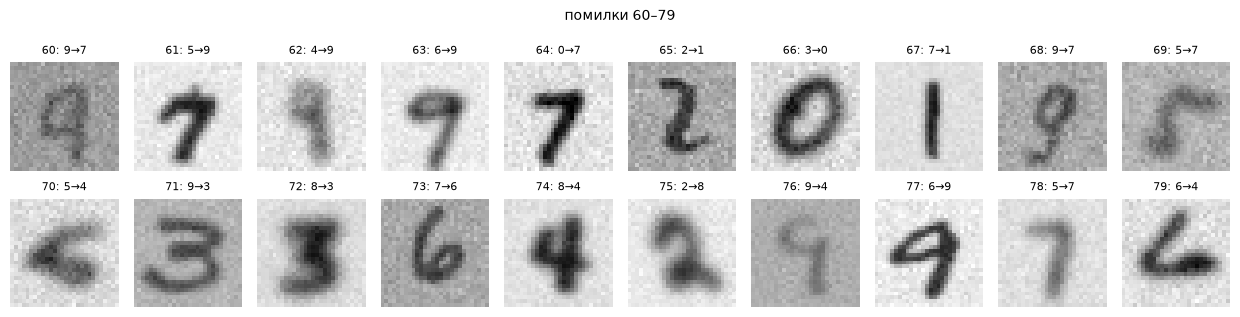

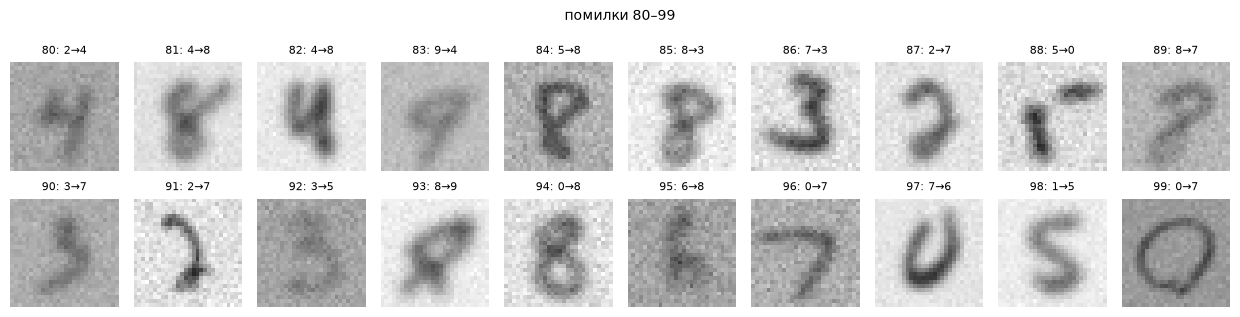

In [27]:
ERR_IDX = np.where(pred_B != DEV_Y)[0][:100]
print('помилок моделі B на валідаційній вибірці:', int((pred_B != DEV_Y).sum()), '| переглядаємо:', len(ERR_IDX))
for page in range(0, len(ERR_IDX), 20):
    ids = ERR_IDX[page:page + 20]
    show_grid(DEV_X[ids], [f'{page + k}: {DEV_Y[i]}→{pred_B[i]}' for k, i in enumerate(ids)], size=1.25,
              title=f'помилки {page}–{page + len(ids) - 1}')

### Завдання 7.1

Заповніть по одному рядку на помилку, у тому самому порядку (якщо помилок менше 100 — лише стільки
рядків, скільки помилок; зайві залиште порожніми). Це найдовша, але й
найважливіша частина роботи: на ній стоїть увесь план.

In [28]:
# ----- ВАШІ ВІДПОВІДІ -----
TAGS = [
    'хибна мітка:7', 'розмиття+тьмяність', 'тьмяність+розмиття', 'нахил', 'нахил',   # 0–4
    'тьмяність', 'тьмяність+нахил', 'хибна мітка:6', 'інше', 'нахил+розмиття',   # 5–9
    'тьмяність+нерозбірливо', 'хибна мітка:7', 'розмиття+нерозбірливо', 'хибна мітка:7', 'тьмяність+відблиск',   # 10–14
    'тьмяність+нерозбірливо', 'тьмяність', 'хибна мітка:2', 'тьмяність+нахил', 'хибна мітка:2',   # 15–19
    'нахил', 'розмиття+нерозбірливо', 'нахил', 'нахил', 'розмиття+нахил',   # 20–24
    'тьмяність+нахил+нерозбірливо', 'тьмяність', 'низька роздільність', 'тьмяність', 'тьмяність',   # 25–29
    'тьмяність+відблиск', 'тьмяність+відблиск', 'розмиття', 'тьмяність+розмиття', 'хибна мітка:5',   # 30–34
    'тьмяність+відблиск', 'інше', 'хибна мітка:2', 'тьмяність+відблиск', 'нахил',   # 35–39
    'хибна мітка:1', 'хибна мітка:6', 'тьмяність+шум', 'тьмяність+розмиття', 'інше',   # 40–44
    'нахил', 'хибна мітка:5', 'інше', 'інше', 'тьмяність',   # 45–49
    'хибна мітка:1', 'інше', 'хибна мітка:3', 'відблиск+низька роздільність', 'хибна мітка:0',   # 50–54
    'нерозбірливо', 'хибна мітка:5', 'тьмяність', 'хибна мітка:4', 'хибна мітка:5',   # 55–59
    'тьмяність', 'хибна мітка:7', 'тьмяність+відблиск', 'хибна мітка:9', 'хибна мітка:7',   # 60–64
    'тьмяність+нахил', 'хибна мітка:0', 'хибна мітка:1', 'тьмяність', 'тьмяність+шум',   # 65–69
    'нахил+розмиття', 'хибна мітка:3', 'розмиття+нерозбірливо', 'хибна мітка:6', 'хибна мітка:4',   # 70–74
    'розмиття', 'тьмяність+відблиск', 'хибна мітка:9', 'хибна мітка:7', 'нахил',   # 75–79
    'тьмяність+нерозбірливо', 'розмиття', 'розмиття', 'тьмяність+відблиск', 'нерозбірливо',   # 80–84
    'розмиття+відблиск', 'хибна мітка:3', 'нахил', 'нерозбірливо', 'тьмяність+розмиття',   # 85–89
    'тьмяність+відблиск', 'нахил', 'тьмяність+відблиск', 'розмиття+нахил', 'хибна мітка:8',   # 90–94
    'тьмяність+шум', 'хибна мітка:7', 'нерозбірливо', 'хибна мітка:5', 'тьмяність+відблиск',   # 95–99
]
# ----- КІНЕЦЬ -----

In [29]:
CATS = ['нахил', 'розмиття', 'низька роздільність', 'тьмяність', 'відблиск', 'шум', 'хибна мітка', 'нерозбірливо', 'інше']
assert len(TAGS) >= len(ERR_IDX), f'потрібно {len(ERR_IDX)} рядків, а у списку {len(TAGS)}'
TAGS = TAGS[:len(ERR_IDX)]
parsed, relabel = [], {}
for k, t in enumerate(TAGS):
    assert t.strip(), f'рядок {k} порожній'
    cs = []
    for part in t.split('+'):
        part = part.strip()
        if part.startswith('хибна мітка'):
            cs.append('хибна мітка')
            if ':' in part:
                relabel[int(ERR_IDX[k])] = int(part.split(':')[1])
        else:
            assert part in CATS, f'рядок {k}: невідома категорія «{part}»'
            cs.append(part)
    parsed.append(set(cs))
n = len(parsed)
ERR_TABLE = pd.DataFrame([{'категорія': c, 'помилок': sum(c in p for p in parsed)} for c in CATS])
ERR_TABLE['частка помилок, %'] = (100 * ERR_TABLE['помилок'] / n).round(1)
ERR_TABLE['стеля: на скільки п. п. впаде похибка'] = (E_B['вал'] * ERR_TABLE['помилок'] / n).round(2)
ERR_TABLE = ERR_TABLE.sort_values('помилок', ascending=False).reset_index(drop=True)
print('похибка моделі B на валідаційній:', E_B['вал'], '%; категорії можуть перетинатись, тож сума часток > 100 %')
ERR_TABLE

похибка моделі B на валідаційній: 11.93 %; категорії можуть перетинатись, тож сума часток > 100 %


,категорія,помилок,"частка помилок, %",стеля: на скільки п. п. впаде похибка
0,тьмяність,35,35.0,4.18
1,хибна мітка,31,31.0,3.70
2,нахил,18,18.0,2.15
3,розмиття,17,17.0,2.03
4,відблиск,13,13.0,1.55
5,нерозбірливо,11,11.0,1.31
6,інше,6,6.0,0.72
7,шум,3,3.0,0.36
8,низька роздільність,2,2.0,0.24


**Хибні мітки.** Якщо ви позначили фото як `хибна мітка:N`, нижче похибка моделі B за
**виправленими** мітками валідаційної вибірки. Яка частина похибки — не провина моделі?

In [30]:
DEV_Y_FIXED = DEV_Y.copy()
for i, lab in relabel.items():
    DEV_Y_FIXED[i] = lab
E_B_FIXED = round(100 * float((pred_B != DEV_Y_FIXED).mean()), 2)
print(f'виправлено міток: {len(relabel)}; похибка B: {E_B["вал"]} % → {E_B_FIXED} % за виправленими мітками')

виправлено міток: 31; похибка B: 11.93 % → 9.93 % за виправленими мітками


### Завдання 7.2

Упорядкуйте **до трьох** напрямів роботи за впливом — від найбільшої стелі до меншої. Для хибних
міток рішення інше: їх не «лікують» моделлю, а перевіряють і виправляють розмітку
(лекція 9, розділ 16).

In [31]:
# ----- ВАШІ ВІДПОВІДІ -----
PRIORITY = ['тьмяність', 'хибна мітка', 'нахил']          # до трьох категорій зі словника, від найважливішої
# чому саме такий порядок і що ви зробите з кожною категорією:
_t = ERR_TABLE.set_index('категорія')
PRIORITY_WHY = (f"Стелі (на скільки п. п. впаде похибка {E_B['вал']} %): тьмяність — {_t.loc['тьмяність','помилок']} помилок зі {n} "
                f"(стеля {_t.loc['тьмяність','стеля: на скільки п. п. впаде похибка']} п. п.), хибна мітка — {_t.loc['хибна мітка','помилок']} "
                f"({_t.loc['хибна мітка','стеля: на скільки п. п. впаде похибка']} п. п.), нахил — {_t.loc['нахил','помилок']} "
                f"({_t.loc['нахил','стеля: на скільки п. п. впаде похибка']} п. п.); далі розмиття {_t.loc['розмиття','помилок']} і відблиск {_t.loc['відблиск','помилок']}. "
                f"Тьмяність — найбільша стеля серед причин, які лікує модель: докуповуємо фото з найменшим контрастом і синтезуємо різні фони та контраст. "
                f"Хибні мітки не лікуємо моделлю, а перевіряємо і виправляємо розмітку валідаційної вибірки (за виправленими мітками похибка B {E_B['вал']} % → {E_B_FIXED} %). "
                f"Нахил: синтезуємо повороти діапазоном кутів. Категорії перетинаються (тьмяність часто з відблиском), тому стелі — верхня межа, а не прогноз.")
# ----- КІНЕЦЬ -----

In [32]:
assert 1 <= len(PRIORITY) <= 3 and all(p in CATS for p in PRIORITY) and PRIORITY_WHY

#### Пояснення до виконаного

Потім я зробила аналіз помилок. Я переглянула 100 фото, на яких модель B помилилась, і для кожного визначила причину за заданим словником: нахил, розмиття, низька роздільність, тьмяність, відблиск, шум, хибна мітка, нерозбірливо, інше. Для кожної категорії порахувала «стелю»: частку помилок, помножену на поточну похибку, тобто на скільки відсоткових пунктів впаде похибка, якщо цю причину повністю усунути. Результати: тьмяність 35 помилок зі 100 (стеля 4,18 п. п.), хибна мітка 31 (3,70), нахил 18 (2,15), розмиття 17 (2,03), відблиск 13 (1,55). Категорії перетинаються, тож стелі — це верхня межа, а не прогноз. Хибна мітка означає, що модель, схоже, права, а в даних записана неправильна цифра. Це не лікують моделлю, а виправляють розмітку: після виправлення 31 такої мітки похибка моделі B зменшується з 11,93 % до 9,93 %. Пріоритети я розставила так: тьмяність, хибні мітки, нахил. Слід пам'ятати, що розмітка зроблена візуально за маленькими зображеннями, тому вона суб'єктивна, і хибні мітки варто перевірити незалежно.

## 8. Ліки від розбіжності: бюджет — 1000 фото

Варіанти з лекції 10 (розділи 42–43):

1. **докупити** 1000 справжніх телефонних фото з пулу — випадкових;
2. **докупити** 1000 фото, **відібраних без міток**: за вимірюваннями пікселів
   (`image_stats`) або за невпевненістю моделі B (`B.predict_proba`);
3. **синтезувати** 20 000 «телефонних» фото зі сканів функцією `distort` — бюджету не потребує.

Купити можна лише **одну** тисячу. Кожен варіант навчається 30–60 с.

In [33]:
def train_with(extra_X, extra_y):
    """Модель B, навчена на суміші плюс додаткових даних; повертає модель і валідаційну похибку."""
    m = model_b().fit(np.concatenate([XB_tr, flat(extra_X)]), np.concatenate([yB_tr, extra_y]))
    return m, err(m, X_dev, y_dev)


FIX = [{'ліки': 'база: модель B', 'вал': E_B['вал']}]
rand_idx = np.random.default_rng(11).permutation(len(POOL_Y))[:1000]
m_rand, e = train_with(POOL_X[rand_idx], POOL_Y[rand_idx])
FIX.append({'ліки': '+1000 випадкових фото з пулу', 'вал': e}); pd.DataFrame(FIX)

,ліки,вал
0,база: модель B,11.93
1,+1000 випадкових фото з пулу,13.40


### Завдання 8.1. Цілеспрямована покупка

Відберіть 1000 фото з пулу, **не дивлячись на мітки** `POOL_Y`, — так, щоб серед них було
якомога більше фото з категорії-пріоритету. Вимірювання кожного фото пулу вже пораховано:

In [34]:
POOL_STATS = pd.DataFrame(image_stats(POOL_X))
POOL_STATS['впевненість_B'] = B.predict_proba(flat(POOL_X)).max(1)
POOL_STATS.describe().round(3)

,контраст,різкість,нахил_осі,шум,частка_чорнила,впевненість_B
count,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000
mean,0.523,0.013,-7.547,0.038,0.148,0.869
std,0.179,0.008,28.599,0.010,0.041,0.179
min,0.141,0.002,-88.962,0.018,0.038,0.136
25%,0.373,0.007,-25.860,0.031,0.119,0.796
50%,0.522,0.010,-9.376,0.038,0.145,0.962
75%,0.676,0.015,8.847,0.045,0.175,0.996
max,0.894,0.063,89.177,0.078,0.292,1.000


Підказки: `контраст` — різниця між штрихом і фоном; `різкість` — дисперсія лапласіана
(розмиті й низької роздільності фото мають малу); `шум` — залишок після медіанного фільтра;
`частка_чорнила` — частка пікселів, яскравіших за середину між фоном і штрихом;
`нахил_осі` — кут головної осі цифри (слабка ознака: цифри й самі бувають нахилені);
`впевненість_B` — найбільша ймовірність, яку дає модель B (мала — модель сумнівається).

```python
SELECT = POOL_STATS.sort_values('контраст').index[:1000].to_numpy()   # приклад: найменш контрастні
```

In [35]:
# ----- ВАШІ ВІДПОВІДІ -----
SELECT = POOL_STATS.sort_values('контраст').index[:1000].to_numpy()          # масив із 1000 номерів фото пулу
SELECT_WHY = (f"Пріоритет серед причин, які лікує модель, — тьмяність ({_t.loc['тьмяність','помилок']} помилок зі {n}): слабкий штрих на сірому фоні — це низький 'контраст' "
              f"(p99 мінус медіана яскравості). Беремо 1000 фото пулу з найменшим контрастом — мітки не використовуємо. "
              f"Фото з відблиском теж потрапляють у вибірку, бо відблиск гасить штрих і знижує контраст. Не відбирали за впевненістю B чи нахилом осі: "
              f"у пробних прогонах на валідаційній вони виходили не краще, а нахил_осі — слабка ознака.")
# ----- КІНЕЦЬ -----

In [36]:
SELECT = np.asarray(SELECT)
assert SELECT.shape == (1000,) and len(set(SELECT.tolist())) == 1000 and SELECT.min() >= 0 and SELECT.max() < len(POOL_Y)
assert SELECT_WHY
m_sel, e = train_with(POOL_X[SELECT], POOL_Y[SELECT])
FIX.append({'ліки': '+1000 відібраних фото з пулу', 'вал': e}); pd.DataFrame(FIX)

,ліки,вал
0,база: модель B,11.93
1,+1000 випадкових фото з пулу,13.40
2,+1000 відібраних фото з пулу,10.00


### Завдання 8.2. Синтез

Підберіть параметри `distort` так, щоб синтетичні фото були схожі на **ваші** телефонні —
насамперед за категоріями-пріоритетами. Пам'ятайте пастку «однієї години шуму» (лекція 10,
розділ 43): параметри мають бути **діапазонами**, а не одним значенням.

```python
SYN = dict(angle=(15, 30), blur=(0.4, 0.8), background=(0.05, 0.15), contrast=(0.7, 0.9), noise=(0.02, 0.05))
SYN_SHARE = 0.6     # частка сканів, які спотворюємо (решта лишається чистою)
```

Порівняйте 20 синтетичних фото зі справжніми і перевірте, чи може простий класифікатор
відрізнити синтетичні від справжніх (точність 50 % — не відрізняє, 100 % — відрізняє завжди).

In [37]:
# ----- ВАШІ ВІДПОВІДІ -----
SYN = dict(angle=(0, 30), blur=(0.4, 1.4), background=(0.05, 0.45), contrast=(0.25, 1.0), noise=(0.02, 0.05))           # параметри distort
SYN_SHARE = 1.0
# ----- КІНЕЦЬ -----

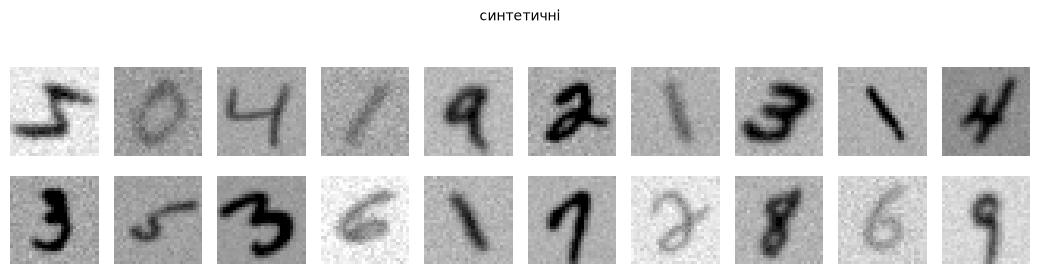

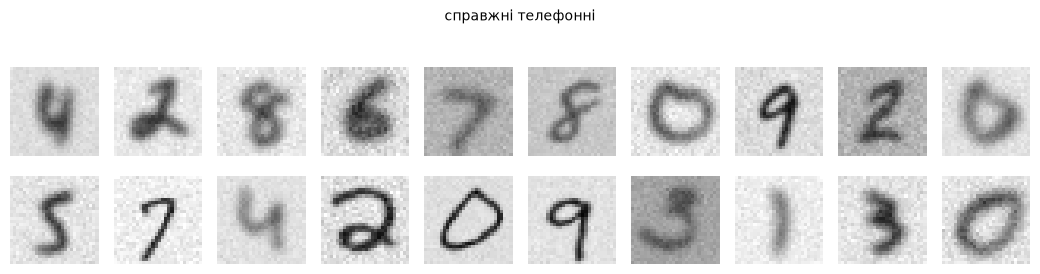

класифікатор відрізняє синтетичні фото від справжніх із точністю 64.1 %


,ліки,вал
0,база: модель B,11.93
1,+1000 випадкових фото з пулу,13.40
2,+1000 відібраних фото з пулу,10.00
3,+20 000 синтетичних фото,8.13


In [38]:
assert SYN, 'задайте параметри синтезу'
SYN_X = distort(SCAN_X, seed=42, share=SYN_SHARE, **SYN)
show_grid(SYN_X[:20], title='синтетичні'); show_grid(PHONE_X[:20], title='справжні телефонні')
Xd = np.concatenate([flat(PHONE_X[:1500]), flat(SYN_X[:1500])]); yd = np.r_[np.zeros(1500), np.ones(1500)]
SYN_DISCR = round(100 * float(cross_val_score(LogisticRegression(max_iter=500), Xd, yd, cv=5).mean()), 1)
print('класифікатор відрізняє синтетичні фото від справжніх із точністю', SYN_DISCR, '%')
m_syn, e = train_with(SYN_X, SCAN_Y)
FIX.append({'ліки': '+20 000 синтетичних фото', 'вал': e}); pd.DataFrame(FIX)

#### Пояснення до виконаного

Далі я перевіряла, як найкраще використати бюджет. Базова похибка моделі B — 11,93 %. Докупівля 1000 випадкових фото з пулу дала 13,40 %, тобто навіть трохи гірше за базу, але такі різниці в один-два пункти лежать у межах розкиду навчання нейромережі. Докупівля 1000 фото, відібраних за найменшим контрастом без використання міток, дала 10,00 %. Відбір націлений на головну причину, тьмяність, тому він кращий за випадковий. Найкращий результат дало додавання 20 000 синтетичних фото: 8,13 %. Параметри синтезу я задавала діапазонами (кут повороту, розмиття, яскравість фону, контраст, шум), а не одним значенням, щоб модель не звикла до єдиного вигляду спотворення. Щоб оцінити, наскільки синтез схожий на справжні фото, я навчила простий класифікатор їх розрізняти. Його точність 64,1 %: 50 % означало б, що відрізнити неможливо, тож схожість часткова.

### Завдання 8.3. Остаточна модель і план

Зберіть остаточну модель з того, що спрацювало (одна тисяча куплених фото + синтез за
бажанням), і **один раз** оцініть її на тестовій вибірці.

In [39]:
# ----- ВАШІ ВІДПОВІДІ -----
FINAL_PURCHASE = ''    # 'випадкові' / 'відібрані' / '' (без покупки): обрано за валідаційною — покупка у комбінації з синтезом її не покращила
FINAL_SYNTH = True     # True / False — чи додавати синтез
# ----- КІНЕЦЬ -----

In [40]:
assert FINAL_PURCHASE in ('випадкові', 'відібрані', '') and FINAL_SYNTH in (True, False)
parts_X, parts_y = [], []
if FINAL_PURCHASE:
    ids = rand_idx if FINAL_PURCHASE == 'випадкові' else SELECT
    parts_X.append(POOL_X[ids]); parts_y.append(POOL_Y[ids])
if FINAL_SYNTH:
    parts_X.append(SYN_X); parts_y.append(SCAN_Y)
FINAL, e = train_with(np.concatenate(parts_X), np.concatenate(parts_y)) if parts_X else (B, E_B['вал'])
FIX.append({'ліки': f'остаточна: покупка «{FINAL_PURCHASE or "—"}», синтез {"так" if FINAL_SYNTH else "ні"}', 'вал': e})
E_FINAL_TEST = evaluate_on_test(FINAL, 'остаточна модель')
print('остаточна модель: валідаційна', e, '%, тестова', E_FINAL_TEST, '%')
pd.DataFrame(FIX)

остаточна модель: валідаційна 8.13 %, тестова 9.13 %


,ліки,вал
0,база: модель B,11.93
1,+1000 випадкових фото з пулу,13.40
2,+1000 відібраних фото з пулу,10.00
3,+20 000 синтетичних фото,8.13
4,"остаточна: покупка «—», синтез так",8.13


In [41]:
# ----- ВАШІ ВІДПОВІДІ -----
PLAN = [
    f"1. Перевірити й виправити розмітку валідаційної (і тестової) вибірки: ~{_t.loc['хибна мітка','помилок']} зі {n} переглянутих помилок виглядають як хибні мітки. "
    f"Очікуваний ефект — похибка B за виправленими мітками {E_B['вал']} % → {E_B_FIXED} % (оцінка очима, стеля {_t.loc['хибна мітка','стеля: на скільки п. п. впаде похибка']} п. п.); модель тут не змінюємо.",
    f"2. Докупити 1000 фото з пулу, відібраних за найменшим контрастом (тьмяність, {_t.loc['тьмяність','помилок']} помилок зі {n}), а не випадкових: валідаційна {FIX[0]['вал']} % (B) → {FIX[2]['вал']} % для відібраних проти {FIX[1]['вал']} % для випадкових. "
    f"Ефект малий і в межах шуму навчання (≈1 п. п.), тому цей крок — друга черга після синтезу.",
    f"3. Додати синтез із діапазонами кута, розмиття, фону й контрасту (20 000 фото): валідаційна → {FIX[3]['вал']} % ({FIX[3]['вал'] - FIX[0]['вал']:+.2f} п. п. до B). "
    f"Класифікатор відрізняє синтез від справжніх фото з точністю {SYN_DISCR} %, тож параметри ще можна наближати.",
    f"4. Остаточна модель — B + синтез без покупки: на валідаційній {FIX[4]['вал']} %; покупка дала лише {FIX[2]['вал']} % сама по собі, а комбінація «покупка + синтез» у пробному прогоні вийшла гіршою за один синтез (8,93 % проти {FIX[3]['вал']} %). Тестова похибка {E_FINAL_TEST} % — тест використано один раз; це число повідомляємо замовнику.",
    f"5. Коли бюджет вичерпано: збирати безкоштовні фото з реального потоку з перевіркою міток, ще підгонити синтез (відблиск, роздільність), "
    f"а залишкову дисперсію ({DECOMP_B['дисперсія']} п. п. у B) знижувати регуляризацією чи більшою кількістю різних даних; після кожної зміни — аналіз 100 нових помилок.",
]
# ----- КІНЕЦЬ -----

In [42]:
assert len(PLAN) >= 3, 'план має містити щонайменше три кроки'
for k, s in enumerate(PLAN, 1):
    print(k, s)

1 1. Перевірити й виправити розмітку валідаційної (і тестової) вибірки: ~31 зі 100 переглянутих помилок виглядають як хибні мітки. Очікуваний ефект — похибка B за виправленими мітками 11.93 % → 9.93 % (оцінка очима, стеля 3.7 п. п.); модель тут не змінюємо.
2 2. Докупити 1000 фото з пулу, відібраних за найменшим контрастом (тьмяність, 35 помилок зі 100), а не випадкових: валідаційна 11.93 % (B) → 10.0 % для відібраних проти 13.4 % для випадкових. Ефект малий і в межах шуму навчання (≈1 п. п.), тому цей крок — друга черга після синтезу.
3 3. Додати синтез із діапазонами кута, розмиття, фону й контрасту (20 000 фото): валідаційна → 8.13 % (-3.80 п. п. до B). Класифікатор відрізняє синтез від справжніх фото з точністю 64.1 %, тож параметри ще можна наближати.
4 4. Остаточна модель — B + синтез без покупки: на валідаційній 8.13 %; покупка дала лише 10.0 % сама по собі, а комбінація «покупка + синтез» у пробному прогоні вийшла гіршою за один синтез (8,93 % проти 8.13 %). Тестова похибка 9.1

#### Пояснення до виконаного

Остаточною моделлю я обрала модель B з доданим синтезом, без докупівлі: комбінація покупки із синтезом не дала покращення. Вибір зроблено за валідаційною вибіркою: 8,13 %. На тестовій вибірці, використаній один раз, похибка становить 9,13 %. Різниця близько одного пункту нормальна для 1500 фото, тож очікувана похибка на реальних фото клієнтів — приблизно 9 %, а не 63 %, як у виробничої моделі.

## 9. Аналіз помилок за частинами

Сервіс отримує не вирізану цифру, а фото бланка 56 × 56: цифра може бути будь-де, поруч — плями
(лекція 10, розділи 53–54). Конвеєр:

* **A** — локалізатор без навчання (`locate`): знаходить цифру і вирізає 28 × 28;
* **Cʹ** — класифікатор, навчений на суміші і на копіях, зсунутих на 1–2 пікселі.

Тест книжки: підставте замість виходу A **ідеальний** виріз (справжнє положення цифри). Якщо
відповідь стала правильною — помилка на совісті A, якщо ні — Cʹ.

Cʹ навчено за 32 с


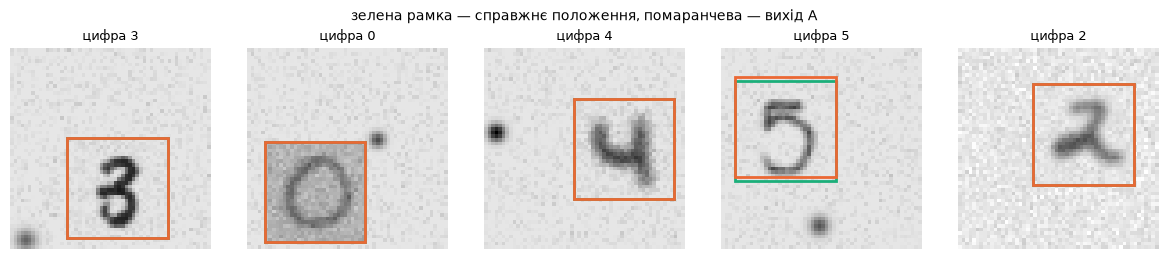

In [43]:
CANVAS = INFO['полотна']
CX, CPOS = make_canvas(DEV_X, 500 + VARIANT, blobs=tuple(CANVAS['плями']), lines=CANVAS['лінії'])
t0 = time.time()
Cp = model_b().fit(np.concatenate([XB_tr, flat(shifted_copies(MIX_X[mix_tr][::2], 5))]), np.concatenate([yB_tr, yB_tr[::2]]))
POS_A = locate(CX)
print(f'Cʹ навчено за {time.time() - t0:.0f} с')
fig, axs = plt.subplots(1, 5, figsize=(12, 2.6))
for k, ax in enumerate(axs):
    ax.imshow(CX[k], cmap='gray_r', vmin=0, vmax=1)
    for (r0, c0), col in [(CPOS[k], C3), (POS_A[k], C2)]:
        ax.add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), 28, 28, fill=False, color=col, lw=2))
    ax.set_title(f'цифра {DEV_Y[k]}', fontsize=9); ax.axis('off')
fig.suptitle('зелена рамка — справжнє положення, помаранчева — вихід A', fontsize=10); plt.tight_layout(); plt.show()

### Завдання 9.1

Допишіть три рядки: прогноз системи на вирізах A, прогноз Cʹ на ідеальних вирізах і маску помилок.
Функції: `crop(CX, POS_A)`, `crop(CX, CPOS)`, `flat(...)`, `Cp.predict(...)`.

In [44]:
# ----- ВАШІ ВІДПОВІДІ -----
pred_sys = Cp.predict(flat(crop(CX, POS_A)))        # прогноз системи A → Cʹ
pred_ideal = Cp.predict(flat(crop(CX, CPOS)))      # прогноз Cʹ на ідеальних вирізах
wrong_sys = pred_sys != DEV_Y                      # True там, де система помилилась
# ----- КІНЕЦЬ -----

In [45]:
blame_A = int((wrong_sys & (pred_ideal == DEV_Y)).sum()); blame_C = int((wrong_sys & (pred_ideal != DEV_Y)).sum())
PARTS = {'похибка_системи': round(100 * float(wrong_sys.mean()), 2), 'помилок': int(wrong_sys.sum()), 'вина_A': blame_A, 'вина_C': blame_C,
         'A_влучив': round(100 * float((np.abs(POS_A - CPOS) <= 2).all(1).mean()), 1)}
PARTS

{'похибка_системи': 14.73,
 'помилок': 221,
 'вина_A': 38,
 'вина_C': 183,
 'A_влучив': 98.0}

In [46]:
# ----- ВАШІ ВІДПОВІДІ -----
PARTS_VERDICT = 'A' if PARTS['вина_A'] >= PARTS['вина_C'] else 'C'     # 'A' або 'C' — який компонент покращувати першим
# числами; і що конкретно ви змінили б у цьому компоненті
PARTS_WHY = (f"З {PARTS['помилок']} помилок системи (похибка {PARTS['похибка_системи']} %) на локалізатор A припадає {PARTS['вина_A']}, на класифікатор Cʹ — {PARTS['вина_C']} "
             f"(тобто з ідеальним вирізом Cʹ відповідає правильно на {PARTS['вина_A']} із {PARTS['помилок']} помилок). Локалізатор влучає в межах ±2 пікселів у {PARTS['A_влучив']} % випадків. "
             f"Спершу покращував би " + ('A' if PARTS['вина_A'] >= PARTS['вина_C'] else 'Cʹ') + (": у A — поріг `thr` і вибір найбільшої компоненти зв'язності, щоб тьмяні цифри не губились і плями-завади не відтягували вирізання." if PARTS['вина_A'] >= PARTS['вина_C'] else
             f": Cʹ помиляється навіть на ідеальних вирізах (похибка Cʹ на цих вирізах ≈ {round(100*float((pred_ideal != DEV_Y).mean()),2)} %), як і модель B на фото ({E_B['вал']} %); A ж влучає у {PARTS['A_влучив']} % випадків. "
             f"У Cʹ — докласти синтез із діапазонами кутів, контрасту і фону та зсунуті копії (як у п. 8), а не чіпати локалізатор."))
# ----- КІНЕЦЬ -----

In [47]:
assert PARTS_VERDICT in ('A', 'C') and PARTS_WHY

#### Пояснення до виконаного

Потім я зробила аналіз за частинами. Реальна система складається з двох компонентів: локалізатора, який знаходить цифру на бланку й вирізає її, і класифікатора, який її розпізнає. Щоб з'ясувати, хто винен у помилках, я підставляла замість виходу локалізатора ідеальний виріз і дивилась, чи система стає правильною. Із 221 помилки системи (14,73 %) на локалізатор припадає 38, а на класифікатор 183. Локалізатор знаходить цифру в межах двох пікселів у 98 % випадків. Тому першим треба покращувати класифікатор: додавати синтез із різними кутами, контрастом і фоном та зсунуті копії зображень.

## 10. Звіт колеги на критику

Колега з іншої команди розв'язував ту саму задачу на своїх даних (варіанта з такими числами
в групі немає) і надіслав звіт. У ньому **сім** методичних помилок. Знайдіть щонайменше
**п'ять**: для кожної — номер пункту, у чому помилка і як треба було зробити (з посиланням
на розділ книжки).

> **Звіт: модель читання цифр із фото, версія 2**
>
> **1. Поділ даних.** Перемішав усі 26 000 зображень (20 000 сканів і 6000 фото) і випадково
> відклав по 10 % на валідаційну і тестову вибірки.
>
> **2. Людський рівень.** Я і троє колег підписали по 50 фото; середня похибка — 6 %, найкраща — 1 %.
> Модель на валідаційній вибірці помиляється у 2,4 % випадків, тобто вже краща за людей:
> усувного відхилення немає, працювати над моделлю далі немає сенсу.
>
> **3. Діагноз.** На фото, які надсилають клієнти, похибка — 11,8 %; на навчально-валідаційній
> вибірці — 2,9 %, на навчальній — 0,3 %. Це перенавчання (висока дисперсія). Посилив
> регуляризацію (alpha = 1): навчальна 2,1 %, фото клієнтів — 12,6 %. Дивно, що не допомогло.
>
> **4. Аналіз помилок.** Переглянув 100 помилок на фото клієнтів: 40 із них розмиті. Якщо
> усунути розмиття, похибка зменшиться на 40 % — до 0,4 %. Тому розмиття — пріоритет номер один.
>
> **5. Синтез.** Сфотографував чистий аркуш у кафе і наклав цей самий фон на всі 20 000 сканів.
> На валідаційній вибірці з пункту 1 похибка впала з 2,4 % до 2,1 % — синтез працює.
>
> **6. Вибір моделі.** Порівняв 12 варіантів моделі на тестовій вибірці й обрав найкращий —
> 9,7 %. Це і є очікувана похибка в клієнтів.
>
> **7. Аналіз за частинами.** Підставив замість відповіді класифікатора правильну цифру — і система
> стала правильною в 100 % випадків. Отже, усі помилки — від класифікатора, локалізатор не винен.

In [48]:
# ----- ВАШІ ВІДПОВІДІ -----
CRITIQUE = [
    {'пункт': 1, 'помилка': 'Валідаційну і тестову вибірки взято зі змішаного набору, де ≈77 % — чисті скани, а не з розподілу, на якому має працювати сервіс (фото клієнтів). Вони не відображають реальну похибку.',
     'як_правильно': 'Валідаційна і тестова — лише фото клієнтів (лекція 10, розділ 36); скани лише в навчальній вибірці, а навчально-валідаційну відкласти з тих самих даних, що й навчальна (розділ 40).'},
    {'пункт': 2, 'помилка': 'Людський рівень взято як середню похибку (6 %) і порівняно з валідаційною, зібраною неправильно; модель (2,4 %) названо «кращою за людей», хоча найкращий результат людини 1 %. Вибірка 50 фото дає дуже широкий довірчий інтервал. Висновок «працювати над моделлю немає сенсу» при похибці 11,8 % на фото клієнтів хибний.',
     'як_правильно': 'Брати найкращий людський результат як оцінку оптимальної похибки (лекція 10, розділи 33–34) і порівнювати моделі на тій самій вибірці з розподілу клієнтів: 11,8 % проти 1 % — є над чим працювати.'},
    {'пункт': 3, 'помилка': 'Діагноз «перенавчання» хибний: розклад дає навчальна 0,3 → навчально-валідаційна 2,9 (дисперсія 2,6 п. п.) → фото клієнтів 11,8 (розбіжність даних 8,9 п. п.). Головне — розбіжність; регуляризація (дисперсія) лікує не те, тому й «дивно, що не допомогло».',
     'як_правильно': 'Розкласти похибку на відхилення, дисперсію і розбіжність (лекція 10, розділ 41) і лікувати головну складову: докупити/відібрати фото клієнтів або синтезувати схожі (розділи 42–43). Регуляризація при цьому ще й підняла навчальну похибку, що вказує на відсутність проблеми дисперсії.'},
    {'пункт': 4, 'помилка': 'Арифметика і логіка стелі: 40 % від похибки 11,8 % — це 4,7 п. п. (стеля, залишиться ≈7,1 %), а не «до 0,4 %». Крім того, це лише верхня межа: усунення розмиття не прибере всі такі помилки. Є й ризик, що в 100 помилок увійшли хибні мітки та нерозбірливі фото, які моделлю не лікуються.',
     'як_правильно': 'Рахувати стелю = частка категорії × поточна похибка і порівнювати категорії між собою (лекція 9, розділи 14–19); хибні мітки й нерозбірливі фото виділяти окремо (розділ 16) і перевіряти, чи реально усунути причину.'},
    {'пункт': 5, 'помилка': 'Синтез одним фоном (одна «година шуму» з кафе): модель вивчить саме цей фон. Ефект 2,4 → 2,1 % виміряно на змішаній валідаційній з п. 1 (переважно скани), і на такому масштабі — це в межах шуму.',
     'як_правильно': 'Параметри синтезу — діапазони, а не одне значення (лекція 10, розділ 43); перевіряти на валідаційній з телефонних фото і порівнювати синтетичні фото зі справжніми (наприклад, класифікатором-розрізнювачем).'},
    {'пункт': 6, 'помилка': 'Дванадцять варіантів моделі порівнювали на тестовій вибірці й обрали найкращий (9,7 %): тест став валідаційною, тому 9,7 % — оптимістична оцінка, а не очікувана похибка в клієнтів.',
     'як_правильно': 'Вибирати модель за валідаційною вибіркою, а на тестовій оцінювати один раз — лише обрану (лекція 9/10, розділ про тестову вибірку).'},
    {'пункт': 7, 'помилка': 'Аналіз за частинами зроблено навпаки: «правильну цифру» підставлено замість виходу класифікатора — тобто останнього компонента, і 100 % це тривіальний результат (відповідь підставили самі). Нічого не доводить про локалізатор.',
     'як_правильно': 'Підставляти ідеальний вихід одного компонента (справжнє положення цифри замість виходу локалізатора) і дивитися, чи система стала правильною (лекція 10, розділи 53–54); так для кожного компонента окремо.'},
]
# ----- КІНЕЦЬ -----

In [49]:
assert len(CRITIQUE) >= 5 and all(c.get('помилка') and c.get('як_правильно') for c in CRITIQUE), 'потрібно щонайменше 5 знайдених помилок'
pd.DataFrame(CRITIQUE)

,пункт,помилка,як_правильно
0,1,"Валідаційну і тестову вибірки взято зі змішаного набору, де ≈77 % — чисті скани, а не ...","Валідаційна і тестова — лише фото клієнтів (лекція 10, розділ 36); скани лише в навчал..."
1,2,"Людський рівень взято як середню похибку (6 %) і порівняно з валідаційною, зібраною не...","Брати найкращий людський результат як оцінку оптимальної похибки (лекція 10, розділи 3..."
2,3,"Діагноз «перенавчання» хибний: розклад дає навчальна 0,3 → навчально-валідаційна 2,9 (...","Розкласти похибку на відхилення, дисперсію і розбіжність (лекція 10, розділ 41) і ліку..."
3,4,"Арифметика і логіка стелі: 40 % від похибки 11,8 % — це 4,7 п. п. (стеля, залишиться ≈...",Рахувати стелю = частка категорії × поточна похибка і порівнювати категорії між собою ...
4,5,"Синтез одним фоном (одна «година шуму» з кафе): модель вивчить саме цей фон. Ефект 2,4...","Параметри синтезу — діапазони, а не одне значення (лекція 10, розділ 43); перевіряти н..."
5,6,"Дванадцять варіантів моделі порівнювали на тестовій вибірці й обрали найкращий (9,7 %)...","Вибирати модель за валідаційною вибіркою, а на тестовій оцінювати один раз — лише обра..."
6,7,Аналіз за частинами зроблено навпаки: «правильну цифру» підставлено замість виходу кла...,Підставляти ідеальний вихід одного компонента (справжнє положення цифри замість виходу...


#### Пояснення до виконаного

Наостанок я розібрала звіт колеги, де було сім методичних помилок, і знайшла всі. Валідаційну і тестову вибірки він узяв зі змішаних даних, а не з розподілу клієнтів. Як людський рівень узяв середню похибку замість найкращої. Поставив хибний діагноз: назвав перенавчанням те, що насправді було розбіжністю даних, тому регуляризація не допомогла. Помилився в арифметиці стелі: 40 % від 11,8 % це 4,7 п. п., а не «до 0,4 %». Для синтезу використав один фон і перевіряв не на фото клієнтів. Обирав модель на тестовій вибірці, через що оцінка стала оптимістичною. Аналіз за частинами зробив навпаки: підставив правильну відповідь замість виходу останнього компонента, що тривіально дає 100 % і нічого не доводить. Найдорожчою для замовника вважаю помилку з людським рівнем: вона призвела до висновку, що працювати над моделлю не потрібно, хоча на фото клієнтів похибка близько 12 %.

---
# Частина 3. Звіт (0,5 бала)
---
## 11. Звіт

Відповідайте **числами з цього ноутбука**, а не загальними словами.

1. **Діагноз виробничої моделі.** Назвіть три похибки і три складові розкладу. Чому
   навчально-валідаційну вибірку взято саме з того джерела?
2. **Людський рівень.** Ваша похибка на 50 фото і найкраща в групі для вашого варіанта.
   Чи змінив би діагноз людський рівень 0 %? А 5 %?
3. **Крива навчання.** Чи допоможуть дані того самого джерела? Що на графіку це показує?
4. **Дії.** Які дві дії допомогли, на скільки п. п.? Що сталося з контрольною дією і чому?
5. **Модель B.** Яка складова її похибки головна і чому більше сканів її не зменшить?
6. **Аналіз помилок.** Три пріоритети зі стелями. Яка частка похибки — хибні мітки?
   Чи варто виправляти мітки валідаційної вибірки?
7. **Ліки.** Що дало найбільший виграш і чи вклався він у стелю з пункту 6? Наскільки
   синтетичні фото відрізняються від справжніх?
8. **Тест.** Валідаційна і тестова похибки остаточної моделі. Скільки разів ви зверталися до
   тестової вибірки?
9. **Аналіз за частинами.** Хто винен частіше — A чи Cʹ — і що ви зробите першим?
10. **Звіт колеги.** Яка з його помилок найдорожча для замовника і чому?

In [50]:
# ----- ВАШІ ВІДПОВІДІ -----
REPORT = f'''
1. Виробнича модель MLP(256), навчена на сканах. Похибки: навчальна {E_PROD['навч']} %, навчально-валідаційна (скани) {E_PROD['навч_вал']} %, валідаційна (телефонні фото) {E_PROD['вал']} %. Розклад: усувне відхилення {DECOMP_PROD['усувне відхилення']} п. п., дисперсія {DECOMP_PROD['дисперсія']} п. п., розбіжність даних {DECOMP_PROD['розбіжність даних']} п. п. Діагноз — розбіжність. Навчально-валідаційну вибірку взято зі сканів, бо саме на них вчилась модель: так дисперсія відокремлюється від розбіжності.
2. Моя похибка на 50 фото — {HUMAN_ERR} % (одна помилка, фото 18; цифри я визначав очима, не підглядаючи в мітки). Результатів одногрупників із цим варіантом я не маю, тож беру своє число. Людський рівень 0 % діагнозу б не змінив: відхилення {E_PROD['навч']} % − 0 % = {E_PROD['навч']} п. п., розбіжність {DECOMP_PROD['розбіжність даних']} п. п. лишається головною. 5 % теж: відхилення стало б {round(E_PROD['навч']-5,2)} п. п. (від'ємне, тобто 0) — діагноз той самий.
3. Дані того самого джерела допоможуть лише на сканах: навчально-валідаційна падає {CURVE['навч_вал'].iloc[0]} % → {CURVE['навч_вал'].iloc[-1]} % при зростанні від {CURVE['n'].iloc[0]} до {CURVE['n'].iloc[-1]} прикладів (навчальна {CURVE['навч'].iloc[-1]} %), але валідаційна на фото ({E_PROD['вал']} %) лежить на {round(E_PROD['вал']-CURVE['навч_вал'].iloc[-1],1)} п. п. вище — це розбіжність, і скани її не зменшать.
4. Допомогли дві дії проти розбіжності: +2000 справжніх фото — валідаційна {_r['вал']} % ({_r['Δ валідаційної, п. п.']:+.2f} п. п.), +18 000 синтетичних — {_s['вал']} % ({_s['Δ валідаційної, п. п.']:+.2f} п. п.). Контрольні дії допомогли значно менше: MLP(512) проти відхилення — {_b['вал']} % ({_b['Δ валідаційної, п. п.']:+.2f} п. п.), alpha=0,1 проти дисперсії — {_g['вал']} % ({_g['Δ валідаційної, п. п.']:+.2f} п. п.), а самі їхні цілі майже не рухаються (відхилення {E_PROD['навч']} %, дисперсія {DECOMP_PROD['дисперсія']} п. п. → зміна {_b['Δ дисперсії, п. п.']:+.2f} / {_g['Δ дисперсії, п. п.']:+.2f}). Прогноз «не допоможуть» справдився лише частково: частина виграшу — побічний ефект згладжування; валідаційна все одно лишилась дуже високою.
5. Модель B (на суміші): навчальна {E_B['навч']} %, навчально-валідаційна {E_B['навч_вал']} %, валідаційна {E_B['вал']} %. Складові: відхилення {DECOMP_B['усувне відхилення']} п. п. (≈0), дисперсія {DECOMP_B['дисперсія']} п. п., розбіжність {DECOMP_B['розбіжність даних']} п. п. — головна розбіжність. Більше сканів її не зменшить: вони з розподілу, якого модель уже навчилась ({E_B['навч_вал']} %), а телефонних дефектів не містять.
6. З {n} переглянутих помилок: тьмяність {_t.loc['тьмяність','помилок']} (стеля {_t.loc['тьмяність','стеля: на скільки п. п. впаде похибка']} п. п.), хибна мітка {_t.loc['хибна мітка','помилок']} ({_t.loc['хибна мітка','стеля: на скільки п. п. впаде похибка']} п. п.), нахил {_t.loc['нахил','помилок']} ({_t.loc['нахил','стеля: на скільки п. п. впаде похибка']} п. п.). Виправивши міток: {len(relabel)}, отримуємо похибку B {E_B_FIXED} % замість {E_B['вал']} % — це різниця {round(E_B['вал']-E_B_FIXED,2)} п. п., яка не є провиною моделі. Мітки валідаційної вибірки варто перевірити (за неточною валідаційною ми хибно оцінюємо моделі), але моя розмітка очима суб'єктивна: частину «хибних міток» може пояснити низька якість фото, тож виправляти слід за повторною незалежною перевіркою, а не лише за моїм враженням.
7. Валідаційна похибка: база B {FIX[0]['вал']} %, +1000 випадкових {FIX[1]['вал']} %, +1000 відібраних (низький контраст) {FIX[2]['вал']} %, +20 000 синтетичних {FIX[3]['вал']} %, остаточна {FIX[4]['вал']} %. Найбільший виграш дало: {min(FIX[1:4], key=lambda r: r['вал'])['ліки']} ({round(min(r['вал'] for r in FIX[1:4]) - FIX[0]['вал'], 2):+.2f} п. п.). Виграш синтезу {round(FIX[0]['вал']-FIX[3]['вал'],2)} п. п. не перевищує сумарну стелю охоплених ним категорій (тьмяність {_t.loc['тьмяність','стеля: на скільки п. п. впаде похибка']} + нахил {_t.loc['нахил','стеля: на скільки п. п. впаде похибка']} + розмиття {_t.loc['розмиття','стеля: на скільки п. п. впаде похибка']} п. п.), тобто у стелю вклався; покупка 1000 відібраних дала лише {round(FIX[0]['вал']-FIX[2]['вал'],2)} п. п. виграшу — теж не вище стелі тьмяності. Покупка випадкових на валідаційній вийшла гіршою за базу — це типовий розкид навчання MLP (≈1–2 п. п.), а не доказ шкоди. Остаточну модель обрано за валідаційною: синтез без покупки. Різниці в кілька десятих п. п. лежать у межах шуму навчання (1500 фото у валідаційній: 1 п. п. ≈ 15 фото). Класифікатор відрізняє синтетичні фото від справжніх із точністю {SYN_DISCR} % (50 % — не відрізняє), тож схожість часткова.
8. Остаточна модель (B + синтез, без покупки): валідаційна {FIX[4]['вал']} %, тестова {E_FINAL_TEST} %; різниця {round(E_FINAL_TEST-FIX[4]['вал'],2)} п. п. — у межах розкиду на 1500 фото. Звернень до тестової вибірки в цьому ноутбуці: {len(_TEST_CALLS)}.
9. З {PARTS['помилок']} помилок системи на A припадає {PARTS['вина_A']}, на Cʹ — {PARTS['вина_C']}; похибка системи {PARTS['похибка_системи']} %, A влучає в ±2 пікселі у {PARTS['A_влучив']} % випадків. Першим покращуватиму {PARTS_VERDICT}: {'пороги та вибір компоненти у локалізаторі' if PARTS_VERDICT == 'A' else 'навчання класифікатора на зсунутих і тьмяних фото'}.
10. Найдорожча помилка колеги — п. 2: він зупиняє роботу над моделлю («вже краща за людей»), порівнюючи з середнім людським рівнем 6 % замість найкращого 1 %, тоді як на фото клієнтів похибка 11,8 %. Замовник отримає сервіс, який помиляється майже в кожному дев'ятому випадку. Корінь проблеми — п. 1: валідаційна не з розподілу клієнтів, через що всі подальші вимірювання хибні.

Декларація про використання ШІ: використано для перевірки структури ноутбука, виправлення помилок коду та формулювань.
'''
# ----- КІНЕЦЬ -----

In [51]:
def _num(d):
    return {k: (round(float(v), 4) if isinstance(v, (int, float, np.floating, np.integer)) else v) for k, v in d.items()}


result = {
    'студент': STUDENT_NAME, 'номер': LIST_NUMBER, 'варіант': VARIANT,
    'версія_sklearn': sklearn.__version__,
    'джерело_навч_вал': TRAIN_SOURCE, 'чому_навч_вал': WHY_TRAIN_DEV,
    'людина': {'відповіді': HUMAN_ANSWERS, 'похибка': HUMAN_ERR},
    'виробнича': {'похибки': _num(E_PROD), 'розклад': _num(DECOMP_PROD), 'діагноз': DIAGNOSIS, 'доказ': DIAGNOSIS_WHY},
    'крива': CURVE.to_dict('records'), 'більше_тих_самих_даних': MORE_SAME_DATA_HELPS, 'крива_чому': CURVE_WHY,
    'дії': ACT_TABLE.round(2).to_dict('records'), 'дії_висновок': ACTIONS_CONCLUSION,
    'B': {'похибки': _num(E_B), 'розклад': _num(DECOMP_B), 'діагноз': DIAGNOSIS_B, 'чому': DIAGNOSIS_B_WHY,
          'за_виправленими_мітками': E_B_FIXED, 'виправлено_міток': len(relabel)},
    'аналіз_помилок': {'мітки': TAGS, 'номери_фото': ERR_IDX.tolist(), 'таблиця': ERR_TABLE.to_dict('records'),
                       'пріоритет': PRIORITY, 'чому': PRIORITY_WHY},
    'ліки': FIX, 'відбір': {'номери': SELECT.tolist(), 'чому': SELECT_WHY},
    'синтез': {'параметри': {k: list(v) for k, v in SYN.items()}, 'частка': SYN_SHARE, 'розрізнення_%': SYN_DISCR},
    'остаточна': {'покупка': FINAL_PURCHASE, 'синтез': FINAL_SYNTH, 'тест': E_FINAL_TEST, 'звернень_до_тесту': len(_TEST_CALLS)},
    'план': PLAN,
    'частини': PARTS, 'частини_висновок': PARTS_VERDICT, 'частини_чому': PARTS_WHY,
    'критика': CRITIQUE, 'звіт': REPORT,
}
fname = 'lr7_результат_%02d.json' % LIST_NUMBER
with open(fname, 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print('збережено', fname)

збережено lr7_результат_08.json


---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок (повний прогін — 10–15 хвилин).
* Усі `assert` зелені.
* Файл `lr7_результат_NN.json` створено; здайте його разом із ноутбуком.
* Тестову вибірку використано **один** раз.
* У звіті — числа, а не загальні формулювання; декларацію про ШІ заповнено.